# Telecom Churn Prediction & Value-Weighted ROI Optimization — Executive Retention PoC (`Company A`)

**Role & Context:** IT Consulting Associate delivering a data-driven and machine learning-backed *Proof of Concept* (**PoC**) proposal for **Company A**, an anonymous wireless telecommunications carrier (~100,000 historical subscribers, limited in-house ML capability).

**Business Focus:** **High-Value & Intervenable Churn** — prioritizing high-ARPU subscribers whose churn risk is driven by operationally actionable levers within a **~30-day proactive retention window** (the target label `churn` captures departures occurring **31–60 days** post-observation).

**Reproducibility:** `RANDOM_STATE = 42` is enforced consistently across all data splits, modeling, and evaluations.

### 9-Section Structure & Completion Status
| Section | Description | Status |
|---|---|---|
| **1. Introduction & Market Analysis** | Company A context, U.S. mature wireless market research & cited benchmarks | **Completed** |
| **2. Setup and Data Loading** | Environment config, portable loader (local/Colab), 1:1 `Client` & `Record` merge | **Completed** |
| **3. Exploratory Data Analysis & Data Audit** | Anomaly audit, MNAR missingness, `NaN`-doc columns, leakage, multicollinearity, value segmentation, intervenability | **Completed** |
| **4. Problem Definition** | Executive problem statement, ML task, 30-day action window, 3 intervention levers | **Completed** |
| **5. Preprocessing & Feature Engineering** | Anomaly handling, missingness flags, multicollinearity pruning, ratio & momentum features | **Completed** |
| **6. Model Building** | 4-model comparison (LogReg, RF, LightGBM, CatBoost) & MNAR ablation study | **Completed** |
| **7. Evaluation** | ROC-AUC, PR-AUC, F1, Accuracy, Brier/ECE, Gains@Top-K HV, Exact TreeSHAP & intervenability | **Completed** |
| **8. From Model to Proposal** | Value-based cutoff optimization, two-scale ROI simulation (sample vs U.S. 0.90%/mo) & sensitivity stress-test | **Completed** |
| **9. Conclusion** | Executive synthesis, implementation risk/mitigation matrix & 6-month PoC-to-production roadmap | **Completed** |


---
## 1. Introduction & Market Analysis

### 1.1 Company A Context & PoC Objective
* **Client Profile:** Company A is a wireless telecommunications operator holding historical billing, usage, network-quality, and customer account data across 100,000 subscribers (`Client.csv` and `Record.csv`), but lacking internal data science and machine learning engineering capacity.
* **The ~30-Day Operational Window:** Per dataset documentation, `churn` records whether a subscriber left **31–60 days after the observation snapshot**. This built-in **~30-day lead time** gives Company A's retention team a practical operational window to execute targeted interventions (device upgrades, plan right-sizing, or proactive customer care) before cancellation intent solidifies.
* **Why *High-Value & Intervenable Churn*?** Not every subscriber carries equal financial value, and not every predictive attribute (such as tenure or geographic area) can be changed by business action. This PoC focuses retention spend strictly where **high revenue exposure** intersects with **actionable levers**.

### 1.2 U.S. Mature Wireless Market & Global Retention Benchmarks
The U.S. wireless industry operates as a saturated, mature market characterized by slowing organic subscriber growth alongside surging data traffic and network capital intensity:

| Market Dimension | Verified Facts & Benchmarks | Strategic Implication for Company A | Source |
|---|---|---|---|
| **U.S. Connection Saturation** | Total U.S. wireless connections reached **579 million** in FY 2024 (~1.7 connections/capita, >259M 5G devices) and surpassed **600 million** in FY 2025 (~1.8 connections/capita; 46% non-phone endpoints). | In a near-saturated market, net growth depends heavily on defending existing high-value relationships rather than costly gross additions alone. | [1], [2] |
| **Traffic Surge vs. Pricing Pressure** | Wireless data consumption rose from **132 trillion MB** (2024) to **159.3 trillion MB** (2025, exceeding the entire 4G decade), requiring **$29B** (2024) and nearly **$30B** (2025; >$763B cumulative) in industry CapEx. Meanwhile, real unlimited plan prices fell **>10%** and cost per GB dropped **>21%**. | Rising CapEx coupled with eroding unit pricing compresses margins, making retention of high-ARPU subscribers critical for protecting ROI on network investments. | [1], [2], [3] |
| **ARPU & Overage Friction** | The FCC documents flat-to-declining industry ARPU driven by aggressive promotions, elimination of legacy overage fees, and heavy reliance on device trade-ins and multi-service bundling to curb switching. | Company A's heavy reliance on overage charges in its top revenue tier (confirmed in Section 3.6) creates bill-shock risk that accelerates competitor switching. | [3] |
| **Major U.S. Carrier Churn Benchmarks** | Monthly postpaid phone churn among leading U.S. carriers stays tightly around **0.76%–0.93%/month**: **AT&T** reported **0.76%** (FY 2024) rising to **0.90%** (FY 2025; Q4 2025: 0.98%, partly from expiring device financing cycles); **T-Mobile** reported **0.86%** (FY 2024) and **0.93%** (FY 2025; Q4 2025: 1.02%). | **Critical Calibration Note:** The 49.56% churn rate in Company A's dataset reflects a *balanced case-control training sample*, not natural market attrition (~0.90%/mo). Stage 5 ROI simulations must recalibrate probabilities to the market base rate. | [4], [5] |
| **Retention vs. Acquisition Economics** | HBR's review of Bain & Company research establishes that acquiring a new customer costs **5×–25× more** than retaining an existing one, while a **5%** increase in customer retention boosts profitability by **25%–95%**. | Preserving high-ARPU customers yields outsized bottom-line impact compared to indiscriminate acquisition spend. | [6], [7] |
| **Proactive AI Retention Impact** | McKinsey demonstrates that AI-enabled *Next-Best-Experience* engines reduce early-life churn, lift B2C revenues by **2%–4%**, raise CSAT by **10%–20%**, and cut service costs by **up to 30%**. Network-CX analytics further identifies subscribers **up to 5× more likely to churn** from poor network quality. | Proactive ML targeting ahead of inbound cancellation calls is empirically validated across global telecom operators. | [8], [9] |

### 1.3 External Market & Industry References
1. CTIA (2025), *2025 Annual Survey Highlights*: https://www.ctia.org/news/2025-annual-survey-highlights
2. CTIA (2026), *2026 Annual Survey Highlights*: https://www.ctia.org/news/2026-annual-survey-highlights
3. Federal Communications Commission / FCC (2024), *2024 Communications Marketplace Report (FCC 24-136)*: https://docs.fcc.gov/public/attachments/FCC-24-136A1.pdf
4. AT&T Inc., *Investor Relations — FY 2024 & FY 2025 Financial Reporting*: https://investors.att.com
5. T-Mobile US, Inc., *Investor Relations — FY 2024 & FY 2025 Financial Reporting / News Releases*: https://investor.t-mobile.com/news-releases
6. Amy Gallo, Harvard Business Review (2014), *The Value of Keeping the Right Customers*: https://hbr.org/2014/10/the-value-of-keeping-the-right-customers
7. Frederick F. Reichheld, Bain & Company, *Prescription for Cutting Costs*: https://www.bain.com/insights/prescription-for-cutting-costs/
8. McKinsey & Company, *Why AI-enabled customer service is key to scaling telco personalization*: https://www.mckinsey.com/industries/technology-media-and-telecommunications/our-insights/why-ai-enabled-customer-service-is-key-to-scaling-telco-personalization
9. McKinsey & Company, *The network is the product: How AI can put telco customer experience in focus*: https://www.mckinsey.com/industries/technology-media-and-telecommunications/our-insights/the-network-is-not-a-black-box-how-ai-can-put-telco-customer-experience-in-focus


---
## 2. Setup and Data Loading

### 2.1 Import Libraries & Reproducibility Configuration
Setting `RANDOM_STATE = 42` and clean executive-ready visualization defaults.


In [1]:
import os
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print(f"Environment ready | pandas={pd.__version__}, numpy={np.__version__}, RANDOM_STATE={RANDOM_STATE}")


Environment ready | pandas=3.0.6, numpy=2.2.0, RANDOM_STATE=42


### 2.2 Portable Data Loader (Relative Repository Path) & 1:1 Table Merge
`Client.csv` (account, handset, and demographic attributes) and `Record.csv` (monthly usage, billing, call quality, and `churn` target) are joined 1:1 via `Customer_ID`.
> *Data Privacy Note:* Place raw dataset files (`Client.csv` and `Record.csv`) inside a local `data/` folder at the repository root (`../data/` when running from `notebooks/`):
> ```text
> telecom-churn-prediction-roi-optimization/data/Client.csv
> telecom-churn-prediction-roi-optimization/data/Record.csv
> ```


In [2]:
def resolve_data_dir() -> Path:
    cwd = Path(os.getcwd())
    candidates = [
        cwd / "data",
        cwd.parent / "data",
    ]
    for p in candidates:
        if (p / "Client.csv").exists() and (p / "Record.csv").exists():
            return p
    raise FileNotFoundError(
        f"Could not locate data/ folder containing Client.csv and Record.csv from: {cwd}. "
        "Place raw CSV files inside ../data/ before executing."
    )

data_dir = resolve_data_dir()
client = pd.read_csv(data_dir / "Client.csv", low_memory=False)
record = pd.read_csv(data_dir / "Record.csv", low_memory=False)

overlap = len(set(client["Customer_ID"]) & set(record["Customer_ID"]))
df = record.merge(client, on="Customer_ID", how="inner")

dtype_summary = df.dtypes.astype(str).value_counts().to_dict()
summary_load = pd.DataFrame([
    {"Table": "Client.csv", "Rows": client.shape[0], "Columns": client.shape[1], "Duplicates": int(client.duplicated().sum()), "Unique_IDs": int(client["Customer_ID"].nunique())},
    {"Table": "Record.csv", "Rows": record.shape[0], "Columns": record.shape[1], "Duplicates": int(record.duplicated().sum()), "Unique_IDs": int(record["Customer_ID"].nunique())},
    {"Table": "Merged (inner)", "Rows": df.shape[0], "Columns": df.shape[1], "Duplicates": int(df.duplicated().sum()), "Unique_IDs": int(df["Customer_ID"].nunique())},
])
print(f"Data directory: {data_dir.name}/ | Customer_ID overlap: {overlap:,} (100% 1:1 exact match)")
print(f"Dtype mix (merged): {dtype_summary}")
display(summary_load)


Data directory: data/ | Customer_ID overlap: 100,000 (100% 1:1 exact match)
Dtype mix (merged): {'float64': 69, 'str': 21, 'int64': 10}


,Table,Rows,Columns,Duplicates,Unique_IDs
0,Client.csv,100000,50,0,100000
1,Record.csv,100000,51,0,100000
2,Merged (inner),100000,100,0,100000


---
## 3. Exploratory Data Analysis & Data Audit

A structured 7-part audit establishes empirical foundations for preprocessing and problem framing:
1. Target distribution (`churn`)
2. Negative values, domain bounds, and semantic discrepancies
3. Grouped missingness patterns & *Informative Missingness* (MNAR)
4. Investigation of 3 columns documented as `NaN` (`recv_sms_Mean`, `iwylis_vce_Mean`, `Customer_ID`)
5. Data leakage, sensitive-attribute ethics, and multicollinearity (`|r| >= 0.95`)
6. Customer value segmentation (*Pareto* & *Revenue at Risk*)
7. Univariate signal strength & *intervenability* overall and inside High-Value Q4

### 3.1 Target Distribution (`churn`)


In [3]:
churn_counts = df["churn"].value_counts().sort_index()
churn_pct = df["churn"].value_counts(normalize=True).sort_index() * 100
target_tbl = pd.DataFrame({
    "Label": ["0 (Stayed / Non-Churn)", "1 (Churned in 31-60 days)"],
    "Subscribers": churn_counts.values,
    "Share_Pct": churn_pct.round(2).values,
})
display(target_tbl)
print("Note: Nearly 50:50 class balance (49.56% churn) confirms balanced/case-control sampling.")


Note: Nearly 50:50 class balance (49.56% churn) confirms balanced/case-control sampling.


,Label,Subscribers,Share_Pct
0,0 (Stayed / Non-Churn),50438,50.440
1,1 (Churned in 31-60 days),49562,49.560


### 3.2 Anomaly, Negative Value & Documentation Discrepancy Audit
Initial log-transformation diagnostics (`np.log1p`) revealed negative values in several telemetry and billing features. Below we audit all negative numeric columns, domain consistency checks, and the true semantics of `change_mou` and `change_rev`.


In [4]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
neg_rows = []
for c in num_cols:
    s = df[c].dropna()
    n_neg = int((s < 0).sum())
    if n_neg > 0:
        neg_rows.append({
            "Column": c,
            "Neg_Count": n_neg,
            "Neg_Pct": round(n_neg / len(df) * 100, 3),
            "Min": round(float(s.min()), 2),
            "Median": round(float(s.median()), 2),
            "Max": round(float(s.max()), 2),
        })
neg_df = pd.DataFrame(neg_rows).sort_values("Neg_Count", ascending=False)
print("=== Numeric Columns Containing Values < 0 ===")
display(neg_df)

domain_checks = pd.DataFrame([
    {"Domain_Check": "eqpdays < 0 (-5 to -1 days)", "Row_Count": int((df["eqpdays"] < 0).sum()),
     "Churn_Rate_Pct": round(df.loc[df["eqpdays"] < 0, "churn"].mean() * 100, 2),
     "Notes": "Likely pre-activation / recent device swap; causes NaN warnings in log1p"},
    {"Domain_Check": "eqpdays > months * 31", "Row_Count": int((df["eqpdays"] > df["months"] * 31).sum()),
     "Churn_Rate_Pct": round(df.loc[df["eqpdays"] > df["months"] * 31, "churn"].mean() * 100, 2),
     "Notes": "Bring-your-own-device (BYOD) or contract reset mismatch"},
    {"Domain_Check": "totmrc_Mean < 0", "Row_Count": int((df["totmrc_Mean"] < 0).sum()),
     "Churn_Rate_Pct": round(df.loc[df["totmrc_Mean"] < 0, "churn"].mean() * 100, 2),
     "Notes": "Recurring monthly charge credits/adjustments (min -26.92)"},
    {"Domain_Check": "rev_Mean <= 0", "Row_Count": int((df["rev_Mean"] <= 0).sum()),
     "Churn_Rate_Pct": round(df.loc[df["rev_Mean"] <= 0, "churn"].mean() * 100, 2),
     "Notes": "Rebates/refunds exceeding charges or zero-billing accounts"},
    {"Domain_Check": "rev_Mean > $500 (Extreme outliers)", "Row_Count": int((df["rev_Mean"] > 500).sum()),
     "Churn_Rate_Pct": round(df.loc[df["rev_Mean"] > 500, "churn"].mean() * 100, 2),
     "Notes": f"Max rev_Mean = ${df['rev_Mean'].max():,.2f}/mo (skews unweighted means)"},
    {"Domain_Check": "actvsubs == 0", "Row_Count": int((df["actvsubs"] == 0).sum()),
     "Churn_Rate_Pct": round(df.loc[df["actvsubs"] == 0, "churn"].mean() * 100, 2),
     "Notes": "Zero active subscribers recorded in household at snapshot"},
])
print("=== Domain Consistency Audit ===")
display(domain_checks)

corr_mou = df["change_mou"].corr(df["mou_Mean"] - df["avg3mou"])
corr_rev = df["change_rev"].corr(df["rev_Mean"] - df["avg3rev"])
print(f"Semantics change_mou vs (mou_Mean - avg3mou): r = {corr_mou:.4f} | range = [{df['change_mou'].min():.1f}, {df['change_mou'].max():.1f}]")
print(f"Semantics change_rev vs (rev_Mean - avg3rev): r = {corr_rev:.4f} | range = [{df['change_rev'].min():.1f}, {df['change_rev'].max():.1f}]")
print("-> Finding: Both columns reflect ABSOLUTE deltas, not percentages as stated in the Dataset Overview.")


=== Numeric Columns Containing Values < 0 ===
=== Domain Consistency Audit ===
Semantics change_mou vs (mou_Mean - avg3mou): r = 0.9025 | range = [-3875.0, 31219.2]
Semantics change_rev vs (rev_Mean - avg3rev): r = 0.9440 | range = [-1107.7, 9963.7]
-> Finding: Both columns reflect ABSOLUTE deltas, not percentages as stated in the Dataset Overview.


,Column,Neg_Count,Neg_Pct,Min,Median,Max
3,change_rev,56150,56.150,"-1,107.740",-0.320,"9,963.660"
2,change_mou,53651,53.651,"-3,875.000",-6.250,"31,219.250"
5,eqpdays,133,0.133,-5.000,342.000,"1,823.000"
1,totmrc_Mean,23,0.023,-26.910,44.990,409.990
0,rev_Mean,5,0.005,-6.170,48.200,"3,843.260"
4,avg6rev,3,0.003,-2.000,50.000,866.000


,Domain_Check,Row_Count,Churn_Rate_Pct,Notes
0,eqpdays < 0 (-5 to -1 days),133,35.340,Likely pre-activation / recent device swap; causes NaN warnings in log1p
1,eqpdays > months * 31,5145,47.790,Bring-your-own-device (BYOD) or contract reset mismatch
2,totmrc_Mean < 0,23,47.830,Recurring monthly charge credits/adjustments (min -26.92)
3,rev_Mean <= 0,17,47.060,Rebates/refunds exceeding charges or zero-billing accounts
4,rev_Mean > $500 (Extreme outliers),69,49.280,"Max rev_Mean = $3,843.26/mo (skews unweighted means)"
5,actvsubs == 0,81,40.740,Zero active subscribers recorded in household at snapshot


### 3.3 Missingness Patterns & *Informative Missingness* (MNAR)
Missing values occur in synchronized blocks across identical customer subsets (`Identical_Mask = True`), and missingness itself carries strong churn signal (*Missing Not At Random* / MNAR).


Total columns with missing values: 43 of 100, grouped into 18 unique mask blocks.
Structural check on avg6*: 91.3% of 2,839 missing rows have tenure months = 6 or 7 (< 6 full months history).


,Column_Block,Num_Cols,Identical_Mask,Missing_Count,Missing_Pct,Churn_If_Missing_Pct,Churn_If_Present_Pct,Delta_pp
0,numbcars,1,True,49366,49.370,50.230,48.910,1.330
1,dwllsize,1,True,38308,38.310,51.030,48.650,2.390
2,HHstatin,1,True,37923,37.920,50.990,48.690,2.300
3,ownrent,1,True,33706,33.710,51.030,48.820,2.210
4,dwlltype,1,True,31909,31.910,51.160,48.810,2.350
5,lor,1,True,30190,30.190,51.360,48.790,2.570
6,income,1,True,25436,25.440,51.430,48.920,2.510
7,adults,1,True,23019,23.020,51.720,48.920,2.800
8,infobase,1,True,22079,22.080,51.980,48.880,3.110
9,hnd_webcap,1,True,10189,10.190,59.150,48.470,10.680


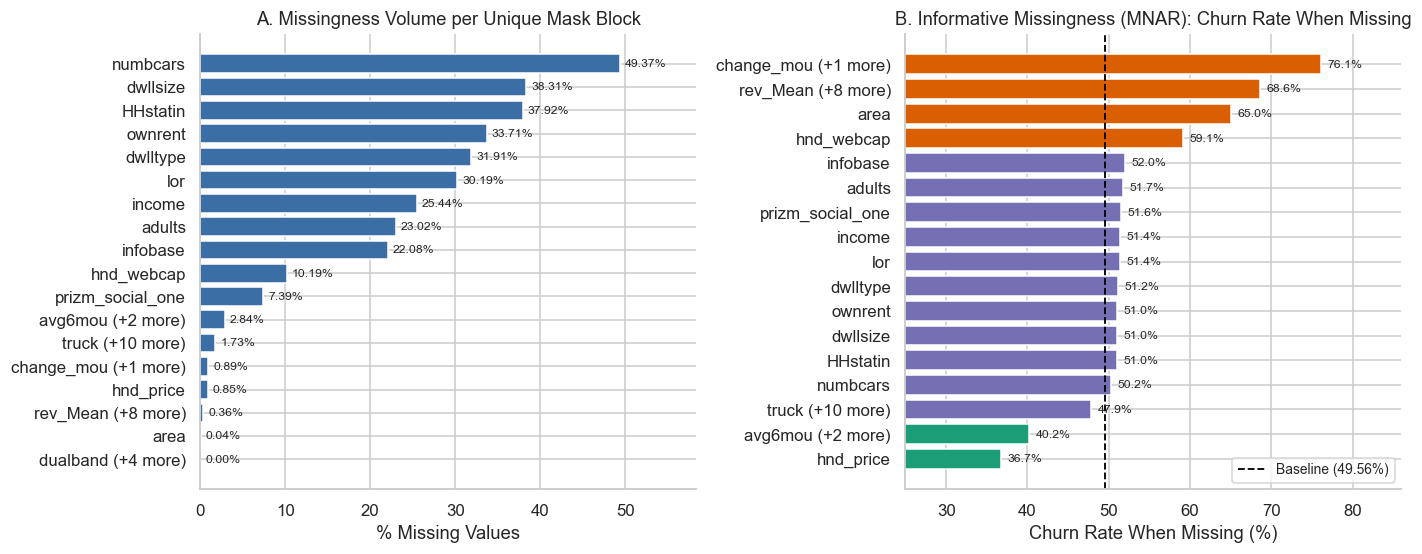

In [5]:
base_churn = df["churn"].mean() * 100
miss_cols = df.columns[df.isna().any()].tolist()
groups = {}
for c in miss_cols:
    groups.setdefault(int(df[c].isna().sum()), []).append(c)

block_rows = []
for cnt, cols in sorted(groups.items(), reverse=True):
    mask = df[cols[0]].isna()
    identical = all((df[c].isna() == mask).all() for c in cols[1:])
    cr_miss = df.loc[mask, "churn"].mean() * 100
    cr_pres = df.loc[~mask, "churn"].mean() * 100
    label = cols[0] if len(cols) == 1 else f"{cols[0]} (+{len(cols)-1} more)"
    block_rows.append({
        "Column_Block": label,
        "Num_Cols": len(cols),
        "Identical_Mask": identical,
        "Missing_Count": cnt,
        "Missing_Pct": round(cnt / len(df) * 100, 2),
        "Churn_If_Missing_Pct": round(cr_miss, 2),
        "Churn_If_Present_Pct": round(cr_pres, 2),
        "Delta_pp": round(cr_miss - cr_pres, 2),
    })

miss_block_df = pd.DataFrame(block_rows)
print(f"Total columns with missing values: {len(miss_cols)} of {df.shape[1]}, grouped into {len(miss_block_df)} unique mask blocks.")
display(miss_block_df)

avg6_months_dist = df.loc[df["avg6mou"].isna(), "months"].value_counts().sort_index()
pct_m67 = avg6_months_dist.loc[avg6_months_dist.index.isin([6, 7])].sum() / len(df.loc[df["avg6mou"].isna()]) * 100
print(f"Structural check on avg6*: {pct_m67:.1f}% of 2,839 missing rows have tenure months = 6 or 7 (< 6 full months history).")

# Visualization Chart 1: Missingness Volume & Informative Missingness
plot_miss = miss_block_df.copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

top_vol = plot_miss.sort_values("Missing_Pct", ascending=True)
axes[0].barh(top_vol["Column_Block"], top_vol["Missing_Pct"], color="#3b6ea5")
axes[0].set_xlabel("% Missing Values")
axes[0].set_title("A. Missingness Volume per Unique Mask Block")
for i, v in enumerate(top_vol["Missing_Pct"]):
    axes[0].text(v + 0.6, i, f"{v:.2f}%", va="center", fontsize=8)
axes[0].set_xlim(0, top_vol["Missing_Pct"].max() + 9)

sig_miss = plot_miss[plot_miss["Missing_Count"] >= 40].sort_values("Churn_If_Missing_Pct", ascending=True)
colors_m = ["#d95f02" if x >= base_churn + 5 else ("#1b9e77" if x <= base_churn - 5 else "#7570b3")
            for x in sig_miss["Churn_If_Missing_Pct"]]
axes[1].barh(sig_miss["Column_Block"], sig_miss["Churn_If_Missing_Pct"], color=colors_m)
axes[1].axvline(base_churn, color="black", linestyle="--", linewidth=1.2, label=f"Baseline ({base_churn:.2f}%)")
axes[1].set_xlabel("Churn Rate When Missing (%)")
axes[1].set_title("B. Informative Missingness (MNAR): Churn Rate When Missing")
for i, v in enumerate(sig_miss["Churn_If_Missing_Pct"]):
    axes[1].text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=8)
axes[1].set_xlim(25, 86)
axes[1].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()


**Key MNAR Insights:**
* Missing values on `change_mou`/`change_rev` (891 rows) exhibit **76.09%** churn (+26.8 pp vs. present), while the 9-column billing block `rev_Mean`/`mou_Mean`/etc. (357 rows) exhibits **68.63%** churn (+19.1 pp) — signaling possible billing disruption prior to account closure.
* Missing `hnd_webcap` (10,189 rows) exhibits **59.15%** churn (+10.7 pp), reflecting legacy non-web-capable devices.
* Conversely, missing `avg6*` (**40.23%** churn) and `hnd_price` (**36.72%** churn) exhibit lower attrition. Hence, Stage 3 preserves missingness flags (`*_isna`) rather than blindly dropping rows or median-imputing alone.

### 3.4 Audit of Undocumented (`NaN` in Dataset Overview) Columns
Three columns had `NaN` descriptions in `ENG_Company _A_ Dataset Overview.docx`: `recv_sms_Mean`, `iwylis_vce_Mean`, and `Customer_ID`.


In [6]:
doc_nan_cols = ["recv_sms_Mean", "iwylis_vce_Mean", "Customer_ID"]
num_df = df.select_dtypes(include=[np.number])
rows_nan_audit = []
for col in doc_nan_cols:
    s = df[col]
    auc = roc_auc_score(df["churn"], s)
    corrs = num_df.corrwith(s).dropna().drop(col, errors="ignore")
    top3 = corrs.reindex(corrs.abs().sort_values(ascending=False).index[:3])
    top3_str = ", ".join(f"{k} ({v:+.2f})" for k, v in top3.items())
    rows_nan_audit.append({
        "Column": col,
        "Zero_Pct": round((s == 0).mean() * 100, 2),
        "Median": round(float(s.median()), 2),
        "Mean": round(float(s.mean()), 2),
        "Max": round(float(s.max()), 1),
        "AUC_vs_Churn": round(auc, 4),
        "Top_3_Correlations": top3_str,
    })

display(pd.DataFrame(rows_nan_audit))
print("Interpretation:")
print("1) recv_sms_Mean: 99.13% zero, AUC 0.4995 (near random; minimal predictive signal).")
print("2) iwylis_vce_Mean: Strongly correlated with mouiwylisv_Mean (r=+0.79) & owylis_vce_Mean (r=+0.73) -> Mean inbound wireless-to-wireless voice calls.")
print("3) Customer_ID: Strongly correlated with months (r=-0.75) -> Chronological cohort ID, NOT random (must be dropped to prevent leakage).")


Interpretation:
1) recv_sms_Mean: 99.13% zero, AUC 0.4995 (near random; minimal predictive signal).
2) iwylis_vce_Mean: Strongly correlated with mouiwylisv_Mean (r=+0.79) & owylis_vce_Mean (r=+0.73) -> Mean inbound wireless-to-wireless voice calls.
3) Customer_ID: Strongly correlated with months (r=-0.75) -> Chronological cohort ID, NOT random (must be dropped to prevent leakage).


,Column,Zero_Pct,Median,Mean,Max,AUC_vs_Churn,Top_3_Correlations
0,recv_sms_Mean,99.130,0.000,0.050,517.300,0.499,"plcd_dat_Mean (+0.04), comp_dat_Mean (+0.04), peak_dat_Mean (+0.04)"
1,iwylis_vce_Mean,30.460,2.000,7.890,519.300,0.464,"mouiwylisv_Mean (+0.79), owylis_vce_Mean (+0.73), recv_vce_Mean (+0.70)"
2,Customer_ID,0.000,"1,050,000.500","1,050,000.500","1,100,000.000",0.475,"months (-0.75), adjrev (-0.48), totrev (-0.47)"


### 3.5 Data Leakage, Sensitive Attribute Ethics & Multicollinearity Audit


Max univariate |AUC - 0.5| = 0.0740 (eqpdays, AUC=0.574) -> No single-column direct target leakage detected.

=== Chronological Sequence Leakage on Customer_ID ===

=== Multicollinearity: 19 feature pairs with |r| >= 0.95 (Top 12) ===


,id_quintile,ID_Min,Mean_Months,Mean_Eqpdays,Churn_Rate_Pct
0,Q1 (Oldest),1000001,32.720,568.260,50.480
1,Q2,1020001,21.780,468.420,49.700
2,Q3,1040001,15.650,359.600,53.800
3,Q4,1060001,11.610,289.420,52.220
4,Q5 (Newest),1080001,12.410,273.970,41.610


,Feature_A,Feature_B,Abs_r
0,totcalls,adjqty,1.000
1,totmou,adjmou,1.000
2,totrev,adjrev,0.999
3,plcd_vce_Mean,attempt_Mean,0.998
4,comp_vce_Mean,complete_Mean,0.998
5,ovrrev_Mean,vceovr_Mean,0.995
6,ccrndmou_Mean,cc_mou_Mean,0.989
7,plcd_vce_Mean,comp_vce_Mean,0.986
8,attempt_Mean,complete_Mean,0.986
9,comp_vce_Mean,attempt_Mean,0.984


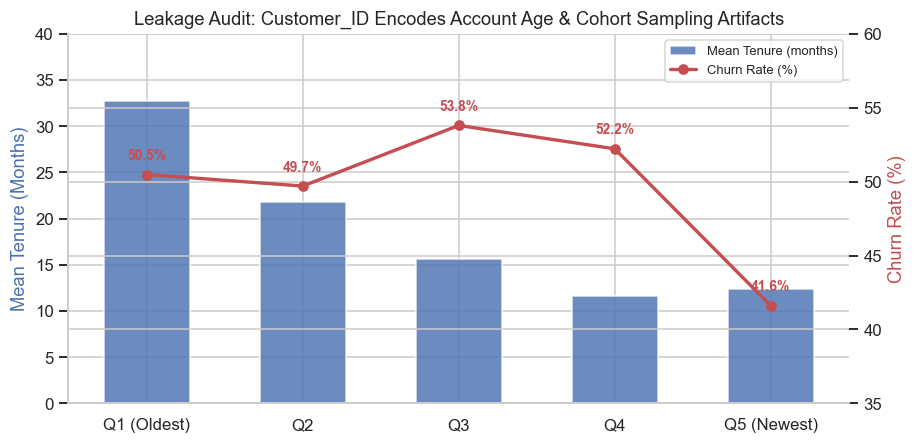

In [7]:
# 1) Univariate ROC-AUC across all numeric features (direct leakage check)
aucs = []
for c in num_df.columns:
    if c == "churn":
        continue
    valid = df[c].notna()
    auc = roc_auc_score(df.loc[valid, "churn"], df.loc[valid, c])
    aucs.append({
        "Feature": c,
        "AUC": round(auc, 4),
        "Abs_Dev": round(abs(auc - 0.5), 4),
        "Mean_Stay": round(float(df.loc[valid & (df["churn"] == 0), c].mean()), 2),
        "Mean_Churn": round(float(df.loc[valid & (df["churn"] == 1), c].mean()), 2),
    })
auc_df = pd.DataFrame(aucs).sort_values("Abs_Dev", ascending=False)
print(f"Max univariate |AUC - 0.5| = {auc_df['Abs_Dev'].max():.4f} ({auc_df.iloc[0]['Feature']}, AUC={auc_df.iloc[0]['AUC']}) -> No single-column direct target leakage detected.")

# 2) Chronological Sequence Leakage Evidence on Customer_ID
df["id_quintile"] = pd.qcut(df["Customer_ID"], 5, labels=["Q1 (Oldest)", "Q2", "Q3", "Q4", "Q5 (Newest)"])
id_q = df.groupby("id_quintile", observed=False).agg(
    ID_Min=("Customer_ID", "min"),
    Mean_Months=("months", "mean"),
    Mean_Eqpdays=("eqpdays", "mean"),
    Churn_Rate_Pct=("churn", lambda s: s.mean() * 100),
).round(2).reset_index()
print("\n=== Chronological Sequence Leakage on Customer_ID ===")
display(id_q)

# 3) Multicollinearity (|r| >= 0.95)
feat_num = [c for c in num_df.columns if c not in ("Customer_ID", "churn")]
corr_mat = df[feat_num].corr().abs()
upper = corr_mat.where(np.triu(np.ones(corr_mat.shape), k=1).astype(bool))
pairs = [(idx, col, round(float(val), 4)) for col in upper.columns for idx, val in upper[col][upper[col] >= 0.95].items()]
pairs.sort(key=lambda x: -x[2])
mc_df = pd.DataFrame(pairs[:12], columns=["Feature_A", "Feature_B", "Abs_r"])
print(f"\n=== Multicollinearity: {len(pairs)} feature pairs with |r| >= 0.95 (Top 12) ===")
display(mc_df)

# Visualization Chart 2: Customer_ID Cohort/Leakage Artifact
fig, ax1 = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(id_q))
ax1.bar(x, id_q["Mean_Months"], color="#4c72b0", alpha=0.82, width=0.55, label="Mean Tenure (months)")
ax1.set_xticks(x)
ax1.set_xticklabels(id_q["id_quintile"])
ax1.set_ylabel("Mean Tenure (Months)", color="#4c72b0")
ax1.set_ylim(0, 40)

ax2 = ax1.twinx()
ax2.spines["top"].set_visible(False)
ax2.plot(x, id_q["Churn_Rate_Pct"], color="#c44e52", marker="o", linewidth=2.2, label="Churn Rate (%)")
ax2.set_ylabel("Churn Rate (%)", color="#c44e52")
ax2.set_ylim(35, 60)
for xi, yi in zip(x, id_q["Churn_Rate_Pct"]):
    ax2.text(xi, yi + 1.0, f"{yi:.1f}%", ha="center", color="#c44e52", fontweight="bold", fontsize=9)

ax1.set_title("Leakage Audit: Customer_ID Encodes Account Age & Cohort Sampling Artifacts")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()


**Leakage & Feature Ethics Summary:**
1. **No direct target leakage:** Maximum univariate `|AUC - 0.5|` is `0.0740`.
2. **`Customer_ID` must be dropped:** Oldest ID quintile (`1000001–1020000`) averages `32.7 months` tenure vs. `12.4 months` in the newest quintile (`1080001–1100000`), where churn drops sharply to `41.6%`.
3. **MNAR billing/change caution:** Missing indicators for `change_mou/rev` (76.1% churn) and billing columns (68.6% churn) will be subjected to a strict **ablation study** in Stage 4 to confirm they do not reflect pre-closure account artifacts.
4. **Sensitive attribute (`ethnic`):** Exhibits an `18.37 pp` spread (`58.1%` vs `39.7%`), but is excluded from modeling for ethical compliance and commercial fairness.
5. **Multicollinearity:** **19 pairs** exhibit `|r| >= 0.95` (e.g., `totcalls`/`adjqty` `1.000`, `totmou`/`adjmou` `1.000`, `totrev`/`adjrev` `0.999`, `plcd_vce_Mean`/`attempt_Mean` `0.998`) and will be pruned in Stage 3.

### 3.6 Customer Value Segmentation (Pareto & *Revenue at Risk*)


Top 20% subscribers (rev_Mean >= $78.83): n=19,929 | Revenue Share=42.17% | Churn=48.47% | Monthly Rev at Risk=$1,206,610/mo


,rev_quartile,Subscribers,Mean_Rev,Rev_Share_Pct,Churn_Pct,Monthly_Rev_At_Risk,Mean_Ovrrev,Mean_DropBlk,Mean_Custcare,Mean_Eqpdays
0,Q1 (Low),24921,24.320,10.360,52.650,"316,672.750",1.310,3.480,0.580,496.420
1,Q2 (Mid-Low),24901,39.320,16.730,47.700,"466,667.920",3.590,7.020,1.500,398.790
2,Q3 (Mid-High),24911,57.210,24.360,49.010,"697,653.220",8.470,10.350,1.920,368.470
3,Q4 (High-Value),24910,114.030,48.550,48.610,"1,389,801.630",40.870,19.410,3.180,300.790


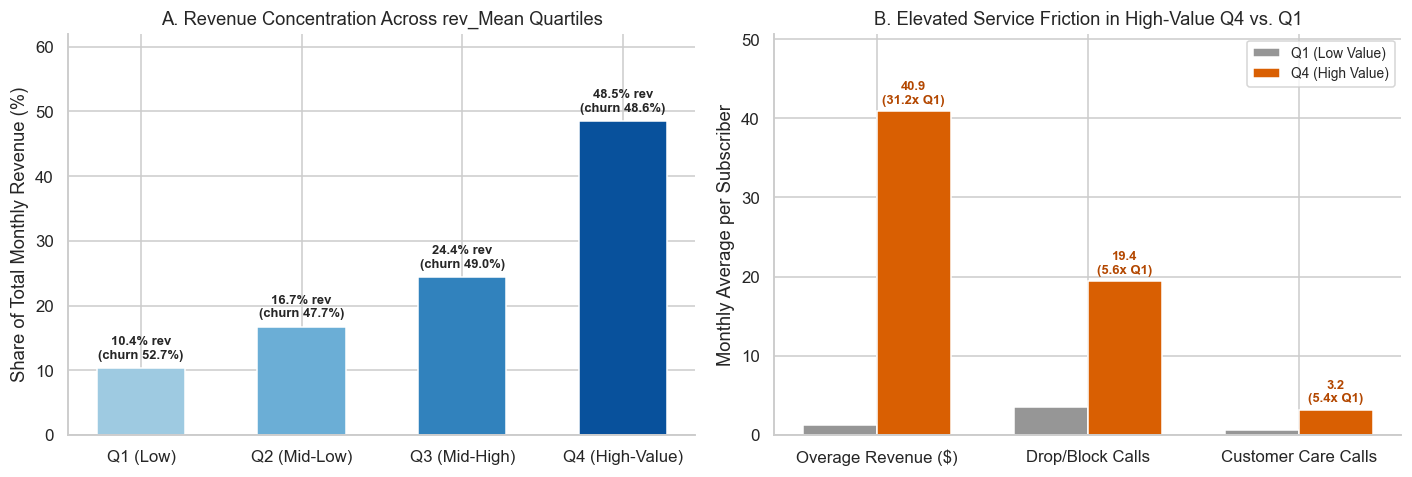

In [8]:
df["rev_quartile"] = pd.qcut(df["rev_Mean"], q=4, labels=["Q1 (Low)", "Q2 (Mid-Low)", "Q3 (Mid-High)", "Q4 (High-Value)"])
qtab = df.groupby("rev_quartile", observed=False).agg(
    Subscribers=("Customer_ID", "count"),
    Mean_Rev=("rev_Mean", "mean"),
    Total_Rev=("rev_Mean", "sum"),
    Churn_Pct=("churn", lambda s: s.mean() * 100),
    Mean_Eqpdays=("eqpdays", "mean"),
    Mean_Ovrrev=("ovrrev_Mean", "mean"),
    Mean_DropBlk=("drop_blk_Mean", "mean"),
    Mean_Custcare=("custcare_Mean", "mean"),
).reset_index()
qtab["Rev_Share_Pct"] = qtab["Total_Rev"] / qtab["Total_Rev"].sum() * 100
qtab["Monthly_Rev_At_Risk"] = df[df["churn"] == 1].groupby("rev_quartile", observed=False)["rev_Mean"].sum().values

cols_show = ["rev_quartile", "Subscribers", "Mean_Rev", "Rev_Share_Pct", "Churn_Pct", "Monthly_Rev_At_Risk", "Mean_Ovrrev", "Mean_DropBlk", "Mean_Custcare", "Mean_Eqpdays"]
display(qtab[cols_show].round(2))

p80 = df["rev_Mean"].quantile(0.80)
top20 = df[df["rev_Mean"] >= p80]
total_rev_all = df["rev_Mean"].sum()
print(f"Top 20% subscribers (rev_Mean >= ${p80:.2f}): n={len(top20):,} | Revenue Share={top20['rev_Mean'].sum()/total_rev_all*100:.2f}% | "
      f"Churn={top20['churn'].mean()*100:.2f}% | Monthly Rev at Risk=${top20.loc[top20['churn']==1, 'rev_Mean'].sum():,.0f}/mo")

# Visualization Chart 3: Revenue Concentration & Service Friction Q4 vs Q1
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

x = np.arange(len(qtab))
axes[0].bar(x, qtab["Rev_Share_Pct"], color=["#9ecae1", "#6baed6", "#3182bd", "#08519c"], width=0.55)
axes[0].set_xticks(x)
axes[0].set_xticklabels(qtab["rev_quartile"])
axes[0].set_ylabel("Share of Total Monthly Revenue (%)")
axes[0].set_ylim(0, 62)
for i, (sh, cr) in enumerate(zip(qtab["Rev_Share_Pct"], qtab["Churn_Pct"])):
    axes[0].text(i, sh + 1.5, f"{sh:.1f}% rev\n(churn {cr:.1f}%)", ha="center", fontsize=8.5, fontweight="bold")
axes[0].set_title("A. Revenue Concentration Across rev_Mean Quartiles")

metrics_lbl = ["Overage Revenue ($)", "Drop/Block Calls", "Customer Care Calls"]
q1_vals = [qtab.loc[0, "Mean_Ovrrev"], qtab.loc[0, "Mean_DropBlk"], qtab.loc[0, "Mean_Custcare"]]
q4_vals = [qtab.loc[3, "Mean_Ovrrev"], qtab.loc[3, "Mean_DropBlk"], qtab.loc[3, "Mean_Custcare"]]
ratios = [b / a for a, b in zip(q1_vals, q4_vals)]

xm = np.arange(len(metrics_lbl))
w = 0.35
axes[1].bar(xm - w/2, q1_vals, width=w, label="Q1 (Low Value)", color="#969696")
axes[1].bar(xm + w/2, q4_vals, width=w, label="Q4 (High Value)", color="#d95f02")
axes[1].set_xticks(xm)
axes[1].set_xticklabels(metrics_lbl)
axes[1].set_ylabel("Monthly Average per Subscriber")
axes[1].set_title("B. Elevated Service Friction in High-Value Q4 vs. Q1")
for i, (v4, r) in enumerate(zip(q4_vals, ratios)):
    axes[1].text(i + w/2, v4 + 1.0, f"{v4:.1f}\n({r:.1f}x Q1)", ha="center", fontsize=8.5, color="#b34700", fontweight="bold")
axes[1].set_ylim(0, max(q4_vals) * 1.24)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


### 3.7 Feature Signal Strength & *Intervenability* (Population & High-Value Q4)


=== Top 12 Numeric Features by Univariate Signal (|AUC - 0.5|) ===
=== Top 8 Categorical Features by Churn Spread (n >= 500) ===
=== Intervenable Lever Test Inside High-Value Q4 (rev_Mean >= $70.75, n=24,913, base churn=48.61%) ===


,Feature,AUC,Abs_Dev,Mean_Stay,Mean_Churn,Action_Category
77,eqpdays,0.574,0.074,363.280,421.090,Intervenable (Device Upgrade)
67,hnd_price,0.442,0.059,108.130,95.540,Intervenable (Handset Tier/Subsidy)
2,totmrc_Mean,0.458,0.043,47.780,44.540,Intervenable (Plan Right-Sizing)
41,mou_opkv_Mean,0.459,0.041,176.780,153.570,Behavioral/Monitoring
28,mou_cvce_Mean,0.459,0.041,241.400,213.880,Behavioral/Monitoring
1,mou_Mean,0.461,0.040,543.210,483.310,Behavioral/Monitoring
33,iwylis_vce_Mean,0.464,0.036,8.550,7.230,Behavioral/Monitoring
39,opk_vce_Mean,0.464,0.036,70.340,61.590,Behavioral/Monitoring
45,complete_Mean,0.464,0.036,115.800,103.420,Behavioral/Monitoring
34,mouiwylisv_Mean,0.464,0.036,19.630,16.730,Behavioral/Monitoring


,Column,Num_Categories,Spread_pp,Highest_Churn,Lowest_Churn
1,crclscod,54,30.940,"A2 (61.6%, n=861)","E4 (30.6%, n=833)"
14,ethnic,18,18.370,"O (58.1%, n=4,198)","Z (39.7%, n=4,425)"
7,hnd_webcap,4,12.070,"MISSING (59.2%, n=10,189)","WCMB (47.1%, n=75,733)"
5,dualband,5,11.490,"N (53.7%, n=23,196)","T (42.2%, n=4,316)"
4,area,20,11.010,"NORTHWEST/ROCKY MOUNTAIN AREA (56.9%, n=4,328)","MIDWEST AREA (45.9%, n=6,346)"
2,asl_flag,2,10.030,"N (51.0%, n=86,064)","Y (40.9%, n=13,936)"
13,dwllsize,16,5.570,"J (51.5%, n=1,430)","L (45.9%, n=512)"
6,refurb_new,3,4.530,"R (53.4%, n=14,406)","N (48.9%, n=85,593)"


,Lever,Segment,n,churn_pct
0,eqpdays (Device Age),<=180d,7912,43.170
1,eqpdays (Device Age),181-365d,9237,47.720
2,eqpdays (Device Age),366-730d,6573,54.430
3,eqpdays (Device Age),>730d,1190,59.500
4,asl_flag (Spending Limit),N,20244,50.260
5,asl_flag (Spending Limit),Y,4669,41.440
6,hnd_webcap (Web Capability),MISSING,1297,58.130
7,hnd_webcap (Web Capability),UNKW,80,38.750
8,hnd_webcap (Web Capability),WC,2272,55.460
9,hnd_webcap (Web Capability),WCMB,21264,47.330


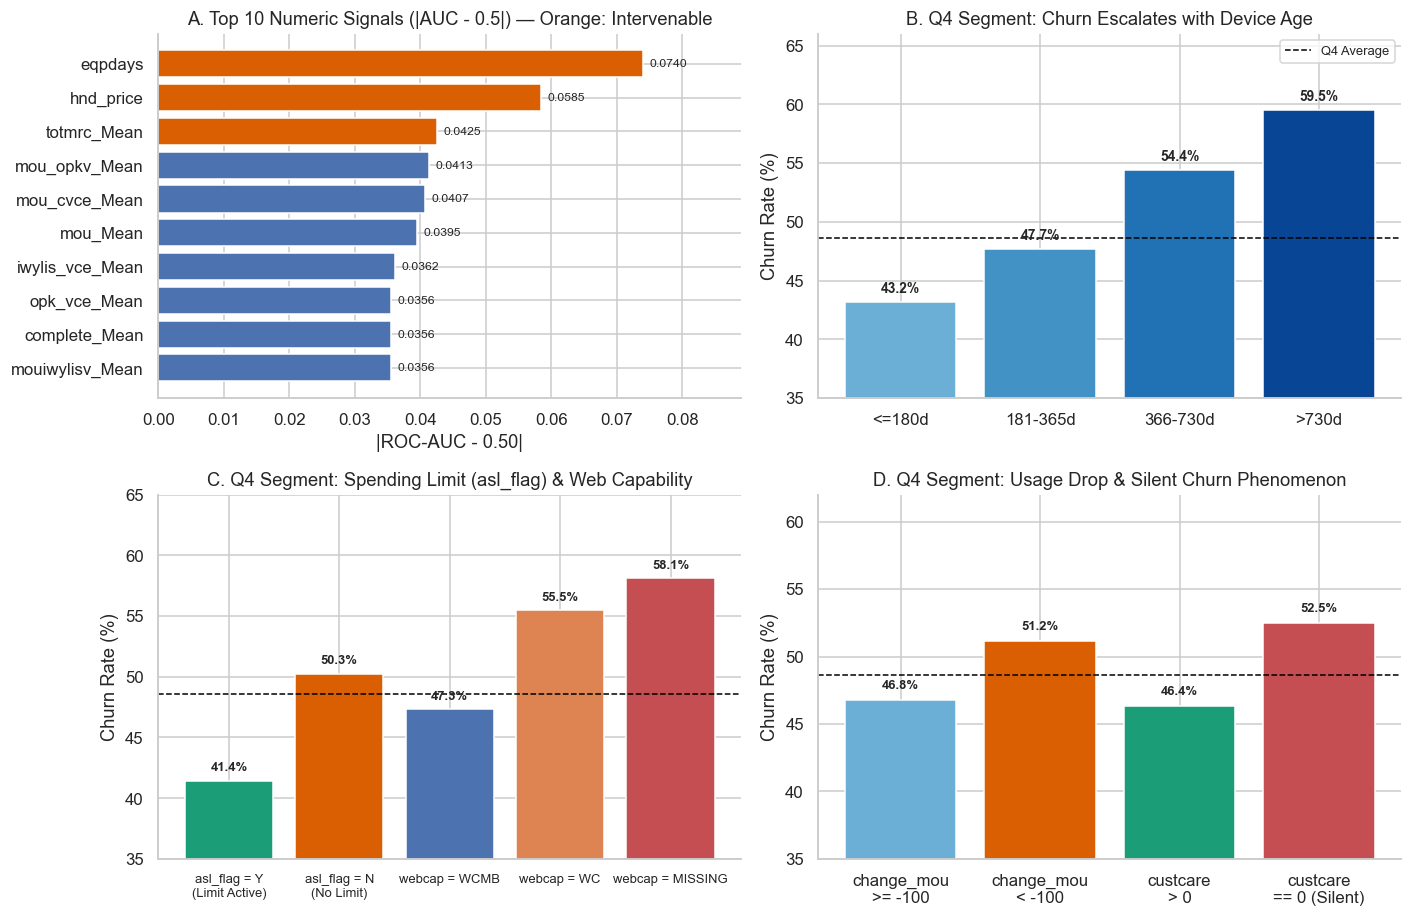

In [9]:
interv_map = {
    "eqpdays": "Intervenable (Device Upgrade)",
    "hnd_price": "Intervenable (Handset Tier/Subsidy)",
    "totmrc_Mean": "Intervenable (Plan Right-Sizing)",
    "mou_opkv_Mean": "Behavioral/Monitoring",
    "mou_cvce_Mean": "Behavioral/Monitoring",
    "mou_Mean": "Behavioral/Monitoring",
    "iwylis_vce_Mean": "Behavioral/Monitoring",
    "opk_vce_Mean": "Behavioral/Monitoring",
    "complete_Mean": "Behavioral/Monitoring",
    "mouiwylisv_Mean": "Behavioral/Monitoring",
    "comp_vce_Mean": "Behavioral/Monitoring",
    "mou_peav_Mean": "Behavioral/Monitoring",
    "change_mou": "Intervenable (Usage Drop Alert)",
    "custcare_Mean": "Intervenable (Proactive Care)",
}

top_num = auc_df[auc_df["Feature"] != "Customer_ID"].head(12).copy()
top_num["Action_Category"] = top_num["Feature"].map(lambda f: interv_map.get(f, "Behavioral/Monitoring"))
print("=== Top 12 Numeric Features by Univariate Signal (|AUC - 0.5|) ===")
display(top_num)

cat_cols = df.select_dtypes(include=["object", "string", "str"]).columns.tolist()
cat_rows = []
for c in cat_cols:
    g = df.groupby(df[c].fillna("MISSING"))["churn"].agg(["count", "mean"])
    g_big = g[g["count"] >= 500]
    if len(g_big) >= 2:
        hi, lo = g_big["mean"].idxmax(), g_big["mean"].idxmin()
        cat_rows.append({
            "Column": c,
            "Num_Categories": len(g),
            "Spread_pp": round((g_big["mean"].max() - g_big["mean"].min()) * 100, 2),
            "Highest_Churn": f"{hi} ({g_big.loc[hi, 'mean']*100:.1f}%, n={g_big.loc[hi, 'count']:,})",
            "Lowest_Churn": f"{lo} ({g_big.loc[lo, 'mean']*100:.1f}%, n={g_big.loc[lo, 'count']:,})",
        })
cat_summary = pd.DataFrame(cat_rows).sort_values("Spread_pp", ascending=False).head(8)
print("=== Top 8 Categorical Features by Churn Spread (n >= 500) ===")
display(cat_summary)

# Intervenable Levers inside High-Value Q4 (rev_Mean >= Q75)
q75 = df["rev_Mean"].quantile(0.75)
hv = df[df["rev_Mean"] >= q75].copy()
hv["eqp_bin"] = pd.cut(hv["eqpdays"], bins=[-10, 180, 365, 730, 5000], labels=["<=180d", "181-365d", "366-730d", ">730d"])

hv_levers = pd.concat([
    hv.groupby("eqp_bin", observed=False)["churn"].agg(n="count", churn_rate="mean").assign(Lever="eqpdays (Device Age)"),
    hv.groupby("asl_flag", dropna=False)["churn"].agg(n="count", churn_rate="mean").assign(Lever="asl_flag (Spending Limit)"),
    hv.groupby(hv["hnd_webcap"].fillna("MISSING"))["churn"].agg(n="count", churn_rate="mean").assign(Lever="hnd_webcap (Web Capability)"),
    hv.groupby(hv["change_mou"] < -100)["churn"].agg(n="count", churn_rate="mean").assign(Lever="change_mou < -100"),
    hv.groupby(hv["refurb_new"].fillna("MISSING"))["churn"].agg(n="count", churn_rate="mean").assign(Lever="refurb_new (New vs Refurb)"),
    hv.groupby(hv["custcare_Mean"] > 0)["churn"].agg(n="count", churn_rate="mean").assign(Lever="custcare_Mean > 0"),
]).reset_index().rename(columns={"index": "Segment"})
hv_levers["churn_pct"] = (hv_levers["churn_rate"] * 100).round(2)
print(f"=== Intervenable Lever Test Inside High-Value Q4 (rev_Mean >= ${q75:.2f}, n={len(hv):,}, base churn={hv['churn'].mean()*100:.2f}%) ===")
display(hv_levers[["Lever", "Segment", "n", "churn_pct"]])

# Visualization Chart 4: Core Signals & High-Value Q4 Action Levers
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

p_top = top_num.head(10).iloc[::-1]
c_top = ["#d95f02" if "Intervenable" in k else "#4c72b0" for k in p_top["Action_Category"]]
axes[0, 0].barh(p_top["Feature"], p_top["Abs_Dev"], color=c_top)
axes[0, 0].set_title("A. Top 10 Numeric Signals (|AUC - 0.5|) — Orange: Intervenable")
axes[0, 0].set_xlabel("|ROC-AUC - 0.50|")
for i, v in enumerate(p_top["Abs_Dev"]):
    axes[0, 0].text(v + 0.001, i, f"{v:.4f}", va="center", fontsize=8)
axes[0, 0].set_xlim(0, p_top["Abs_Dev"].max() + 0.015)

eqp_g = hv.groupby("eqp_bin", observed=False)["churn"].mean() * 100
axes[0, 1].bar(eqp_g.index.astype(str), eqp_g.values, color=["#6baed6", "#4292c6", "#2171b5", "#084594"])
axes[0, 1].axhline(hv["churn"].mean() * 100, color="black", linestyle="--", linewidth=1, label="Q4 Average")
axes[0, 1].set_title("B. Q4 Segment: Churn Escalates with Device Age")
axes[0, 1].set_ylabel("Churn Rate (%)")
axes[0, 1].set_ylim(35, 66)
for i, v in enumerate(eqp_g.values):
    axes[0, 1].text(i, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=9)
axes[0, 1].legend(fontsize=8.5)

c_labels = ["asl_flag = Y\n(Limit Active)", "asl_flag = N\n(No Limit)", "webcap = WCMB", "webcap = WC", "webcap = MISSING"]
c_vals = [
    hv.loc[hv["asl_flag"] == "Y", "churn"].mean() * 100,
    hv.loc[hv["asl_flag"] == "N", "churn"].mean() * 100,
    hv.loc[hv["hnd_webcap"] == "WCMB", "churn"].mean() * 100,
    hv.loc[hv["hnd_webcap"] == "WC", "churn"].mean() * 100,
    hv.loc[hv["hnd_webcap"].isna(), "churn"].mean() * 100,
]
axes[1, 0].bar(c_labels, c_vals, color=["#1b9e77", "#d95f02", "#4c72b0", "#dd8452", "#c44e52"])
axes[1, 0].axhline(hv["churn"].mean() * 100, color="black", linestyle="--", linewidth=1)
axes[1, 0].set_title("C. Q4 Segment: Spending Limit (asl_flag) & Web Capability")
axes[1, 0].set_ylabel("Churn Rate (%)")
axes[1, 0].set_ylim(35, 65)
axes[1, 0].tick_params(axis="x", labelsize=8.5)
for i, v in enumerate(c_vals):
    axes[1, 0].text(i, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=8.5)

d_labels = ["change_mou\n>= -100", "change_mou\n< -100", "custcare\n> 0", "custcare\n== 0 (Silent)"]
d_vals = [
    hv.loc[hv["change_mou"] >= -100, "churn"].mean() * 100,
    hv.loc[hv["change_mou"] < -100, "churn"].mean() * 100,
    hv.loc[hv["custcare_Mean"] > 0, "churn"].mean() * 100,
    hv.loc[hv["custcare_Mean"] == 0, "churn"].mean() * 100,
]
axes[1, 1].bar(d_labels, d_vals, color=["#6baed6", "#d95f02", "#1b9e77", "#c44e52"])
axes[1, 1].axhline(hv["churn"].mean() * 100, color="black", linestyle="--", linewidth=1)
axes[1, 1].set_title("D. Q4 Segment: Usage Drop & Silent Churn Phenomenon")
axes[1, 1].set_ylabel("Churn Rate (%)")
axes[1, 1].set_ylim(35, 62)
for i, v in enumerate(d_vals):
    axes[1, 1].text(i, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=8.5)

plt.tight_layout()
plt.show()


**Counter-Intuitive Findings Guiding Stage 3 Feature Engineering:**
* **`custcare_Mean == 0` exhibits higher churn** (`51.76%` overall; `52.50%` in Q4 vs. `46.35%` when `custcare_Mean > 0`). Subscribers who contact support and get issues resolved stay longer than **silent churners** whose usage quietly drops (`change_mou < -100`) before defecting.
* **Raw `drop_blk_Mean` appears inverted in Q4** (`47.52%` when `>15` vs. `49.49%` when `<=15`) due to **call-volume confounding** (`attempt_Mean`). Normalizing failures by attempt volume (`drop_blk_rate`, `drop_vce_rate`) is essential in Stage 3.


---
## 4. Problem Definition

### 4.1 Executive Business Question
> *"Can Company A accurately identify which high-value subscribers face elevated churn risk **31–60 days ahead**, giving retention teams a **~30-day operational window** to deploy targeted, cost-effective interventions—specifically aging-device upgrades, bill-shock protection, and proactive outreach for silent usage drops?"*

### 4.2 ML Task & Value-Weighted Decision Framework
* **ML Task:** *Supervised Binary Classification* estimating $p_i = P(\text{churn}_i = 1 \mid X_i)$ over the 31–60 day forward window.
* **Value-Based Prioritization:** Predicted risk is paired with customer revenue via **Expected Monthly Revenue at Risk**:
  $$\text{Expected Revenue at Risk}_i = p_i \times \text{rev\_Mean}_i$$
  This shifts retention focus away from low-ARPU accounts (`Q1`: `$24.32/mo`) toward `Q4` (`$114.03/mo`, `48.55%` of total revenue) and the `Top 20%` (`$1.21M/mo` at risk in the sample).
* **Three Actionable Retention Levers (30-Day Execution Window):**
  1. **Device Modernization & Trade-In (`eqpdays > 365`, `hnd_webcap = WC/MISSING`):** In Q4, churn jumps from `43.17%` (`<=180d`) to `59.50%` (`>730d`). Targeted trade-in/installment offers lock in loyalty while improving device experience.
  2. **Bill-Shock Protection & Plan Right-Sizing (`asl_flag = N`, elevated `ovrrev_Mean`):** Q4 subscribers average `$40.87/mo` in overage charges (`31.2×` Q1), while accounts with a spending limit (`asl_flag = Y`) exhibit **8.82 pp lower churn** (`41.44%` vs `50.26%`).
  3. **Proactive Care for Silent Churn & Network Friction (`change_mou < -50` & `custcare_Mean == 0`, high `drop_vce_rate`):** Priority outbound support and goodwill bill credits before defection occurs.


---
## 5. Preprocessing & Feature Engineering

Guided by the Stage 2 audit, preprocessing follows a strict **zero-leakage architecture**:
1. **Deterministic Row-Level Engineering (pre-split):** create 8 anomaly/MNAR flags, clip `eqpdays < 0` to `0`, engineer 19 domain-ratio/momentum features, and drop leakage (`Customer_ID`), sensitive (`ethnic`), noise (`recv_sms_Mean`), and 14 collinear columns (`|r| >= 0.95`).
2. **Fit-on-Train-Only Transformations (post-70/15/15 stratified split):** maintain a **Tree-Ready** pipeline (native numeric `NaN` + `"MISSING"` `category` dtype) and a **Linear-Ready** pipeline (`SimpleImputer(median)` + `RobustScaler` and `OneHotEncoder(min_frequency=100)` fit exclusively on Train).


In [10]:
DROP_LEAK_ETHICS_NOISE = ["Customer_ID", "ethnic", "recv_sms_Mean"]
DROP_MULTICOLLINEAR = [
    "adjqty", "adjmou", "adjrev",
    "attempt_Mean", "complete_Mean", "vceovr_Mean", "cc_mou_Mean", "plcd_dat_Mean",
    "comp_vce_Mean", "avg3mou", "avg3qty", "inonemin_Mean", "mou_opkd_Mean", "ovrmou_Mean",
]
EDA_TEMP_COLS = ["id_quintile", "rev_quartile"]


def engineer_and_clean_features(df_raw: pd.DataFrame):
    # Separate business metadata for Stage 4-5 ROI evaluation (excluded from model features)
    meta = pd.DataFrame({
        "Customer_ID": df_raw["Customer_ID"],
        "rev_Mean_raw": df_raw["rev_Mean"],
        "rev_quartile": pd.qcut(
            df_raw["rev_Mean"], q=4,
            labels=["Q1 (Low)", "Q2 (Mid-Low)", "Q3 (Mid-High)", "Q4 (High-Value)"]
        ),
        "eqpdays_raw": df_raw["eqpdays"],
        "asl_flag": df_raw["asl_flag"],
        "hnd_webcap": df_raw["hnd_webcap"].fillna("MISSING"),
    }, index=df_raw.index)

    work = df_raw.drop(columns=[c for c in EDA_TEMP_COLS if c in df_raw.columns]).copy()
    raw_feat_count = work.shape[1] - 1  # exclude target churn

    # 1. Anomaly & Informative Missingness (MNAR) Indicators - 8 binary flags
    work["eqpdays_neg_flag"] = (work["eqpdays"] < 0).astype(int)
    work["eqpdays_exceeds_tenure"] = (work["eqpdays"] > work["months"] * 31).astype(int)
    work["billing_credit_flag"] = ((work["rev_Mean"] <= 0) | (work["totmrc_Mean"] < 0)).astype(int)
    work["miss_billing_flag"] = work["rev_Mean"].isna().astype(int)
    work["miss_change_flag"] = work["change_mou"].isna().astype(int)
    work["miss_webcap_flag"] = work["hnd_webcap"].isna().astype(int)
    work["miss_avg6_flag"] = work["avg6mou"].isna().astype(int)
    work["miss_hnd_price_flag"] = work["hnd_price"].isna().astype(int)

    # 2. Clip negative eqpdays to 0 (signal preserved in eqpdays_neg_flag)
    work["eqpdays"] = work["eqpdays"].clip(lower=0)

    # 3. Domain-Engineered Features (19 features)
    # A. Network quality & service ratios (resolving call-volume confounding)
    work["drop_blk_rate"] = work["drop_blk_Mean"] / (work["attempt_Mean"] + 1.0)
    work["drop_vce_rate"] = work["drop_vce_Mean"] / (work["plcd_vce_Mean"] + 1.0)
    work["unan_rate"] = work["unan_vce_Mean"] / (work["plcd_vce_Mean"] + 1.0)
    work["comp_rate"] = work["complete_Mean"] / (work["attempt_Mean"] + 1.0)
    work["custcare_per_attempt"] = work["custcare_Mean"] / (work["attempt_Mean"] + 1.0)

    # B. Handset lifecycle
    work["eqp_to_tenure_ratio"] = work["eqpdays"] / (work["months"] * 30.4375 + 1.0)
    work["phones_per_year"] = work["phones"] / (work["months"] / 12.0)

    # C. Billing structure & bill-shock exposure
    work["rev_per_mou"] = work["rev_Mean"].clip(lower=0.0) / (work["mou_Mean"] + 1.0)
    work["ovr_rev_share"] = work["ovrrev_Mean"] / work["rev_Mean"].clip(lower=1.0)
    work["ovr_mou_share"] = work["ovrmou_Mean"] / (work["mou_Mean"] + 1.0)
    work["mrc_to_rev_ratio"] = work["totmrc_Mean"].clip(lower=0.0) / work["rev_Mean"].clip(lower=1.0)

    # D. Usage momentum & silent churn risk
    work["mou_trend_3v6"] = work["avg3mou"] - work["avg6mou"]
    work["rev_trend_3v6"] = work["avg3rev"] - work["avg6rev"]
    work["qty_trend_3v6"] = work["avg3qty"] - work["avg6qty"]
    work["mou_pct_change_3m"] = work["change_mou"] / (work["avg3mou"] + 1.0)
    work["rev_pct_change_3m"] = work["change_rev"] / work["avg3rev"].clip(lower=1.0)
    work["silent_churn_risk"] = ((work["change_mou"] < -50) & (work["custcare_Mean"] == 0)).astype(int)
    work["peak_to_total_mou"] = work["mou_peav_Mean"] / (work["mou_peav_Mean"] + work["mou_opkv_Mean"] + 1.0)
    work["actv_sub_ratio"] = work["actvsubs"] / (work["uniqsubs"] + 1e-6)

    new_feat_names = [
        "eqpdays_neg_flag", "eqpdays_exceeds_tenure", "billing_credit_flag",
        "miss_billing_flag", "miss_change_flag", "miss_webcap_flag", "miss_avg6_flag", "miss_hnd_price_flag",
        "drop_blk_rate", "drop_vce_rate", "unan_rate", "comp_rate", "custcare_per_attempt",
        "eqp_to_tenure_ratio", "phones_per_year",
        "rev_per_mou", "ovr_rev_share", "ovr_mou_share", "mrc_to_rev_ratio",
        "mou_trend_3v6", "rev_trend_3v6", "qty_trend_3v6",
        "mou_pct_change_3m", "rev_pct_change_3m", "silent_churn_risk",
        "peak_to_total_mou", "actv_sub_ratio",
    ]

    # 4. Drop forbidden & redundant columns AFTER derived features are created
    drop_all = DROP_LEAK_ETHICS_NOISE + DROP_MULTICOLLINEAR
    work = work.drop(columns=drop_all)
    return work, meta, new_feat_names, raw_feat_count


df_fe, meta_df, engineered_cols, raw_feat_cnt = engineer_and_clean_features(df)

# Verify zero remaining raw collinear pairs |r| >= 0.95
rem_raw_num = [
    c for c in df_fe.select_dtypes(include=[np.number]).columns
    if c not in engineered_cols and c != "churn"
]
corr_rem = df_fe[rem_raw_num].corr().abs()
upper_rem = corr_rem.where(np.triu(np.ones(corr_rem.shape), k=1).astype(bool))
rem_mc_pairs = [(i, j) for j in upper_rem.columns for i in upper_rem.index if upper_rem.loc[i, j] >= 0.95]

dim_audit = pd.DataFrame([
    {"Stage": "Initial Merged Dataset", "Rows": df.shape[0], "Features": raw_feat_cnt, "Details": "99 raw features (excl. churn)"},
    {"Stage": "Drop Leakage/Ethics/Noise (-3)", "Rows": df.shape[0], "Features": raw_feat_cnt - 3, "Details": "Customer_ID, ethnic, recv_sms_Mean"},
    {"Stage": "Drop Collinear |r|>=0.95 (-14)", "Rows": df.shape[0], "Features": raw_feat_cnt - 17, "Details": f"Remaining raw |r|>=0.95 pairs: {len(rem_mc_pairs)}"},
    {"Stage": "Add Engineered Features (+27)", "Rows": df_fe.shape[0], "Features": df_fe.shape[1] - 1, "Details": "8 MNAR/anomaly flags + 19 ratio/delta features"},
])
display(dim_audit)
assert len(rem_mc_pairs) == 0, f"Remaining collinear pairs found: {rem_mc_pairs}"
assert not any(c in df_fe.columns for c in DROP_LEAK_ETHICS_NOISE), "Forbidden columns still present!"
print("Clean audit passed: Customer_ID, ethnic, recv_sms_Mean removed; remaining raw |r|>=0.95 pairs = 0.")


Clean audit passed: Customer_ID, ethnic, recv_sms_Mean removed; remaining raw |r|>=0.95 pairs = 0.


,Stage,Rows,Features,Details
0,Initial Merged Dataset,100000,99,99 raw features (excl. churn)
1,Drop Leakage/Ethics/Noise (-3),100000,96,"Customer_ID, ethnic, recv_sms_Mean"
2,Drop Collinear |r|>=0.95 (-14),100000,82,Remaining raw |r|>=0.95 pairs: 0
3,Add Engineered Features (+27),100000,109,8 MNAR/anomaly flags + 19 ratio/delta features


=== Top 12 Engineered Features by Univariate Signal (|AUC - 0.5|) ===
=== Engineered Lever Validation in High-Value Q4 ===


,Engineered_Feature,Missing,AUC,Abs_Dev,Mean_Stay,Mean_Churn
14,phones_per_year,1,0.451,0.049,1.357,1.245
15,rev_per_mou,357,0.548,0.048,0.481,1.016
22,mou_pct_change_3m,891,0.457,0.043,0.335,0.423
13,eqp_to_tenure_ratio,1,0.542,0.042,0.710,0.764
11,comp_rate,0,0.467,0.033,0.691,0.662
18,mrc_to_rev_ratio,357,0.470,0.030,0.910,0.881
12,custcare_per_attempt,0,0.475,0.025,0.011,0.010
19,mou_trend_3v6,2839,0.479,0.021,11.872,1.248
17,ovr_mou_share,357,0.520,0.020,0.058,0.070
5,miss_webcap_flag,0,0.519,0.019,0.083,0.122


,Q4_Segment,n,Churn_Pct
0,drop_blk_rate <= p75 (0.083),18682,47.410
1,drop_blk_rate > p75 (0.083),6228,52.200
2,silent_churn_risk == 0,21060,47.330
3,silent_churn_risk == 1 (MOU drop & 0 care),3850,55.580


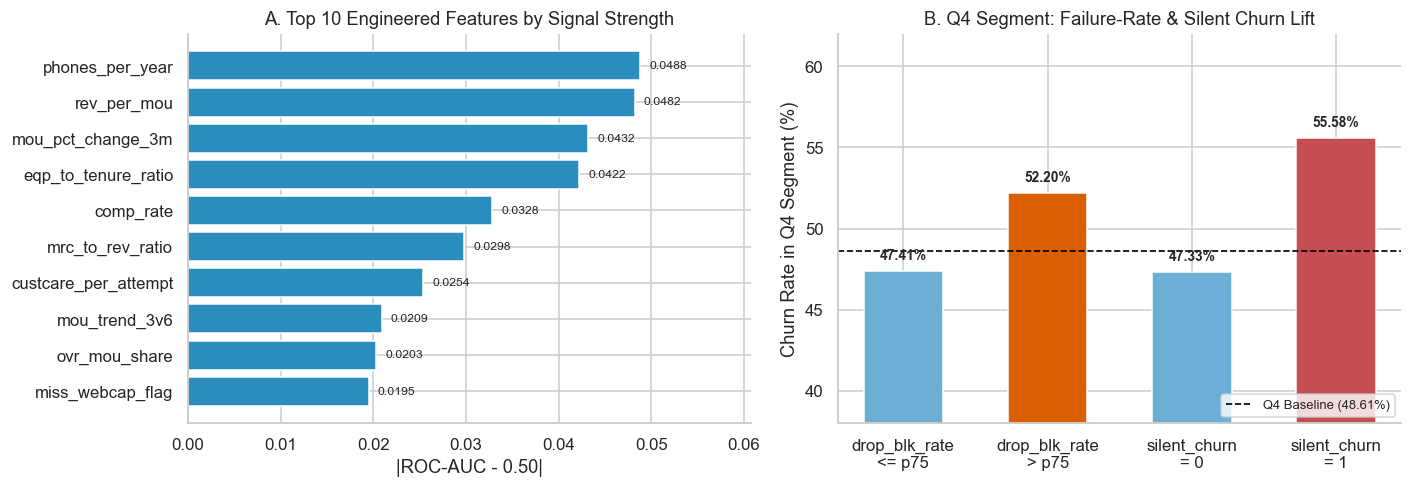

In [11]:
# Validate univariate signal of engineered features & confounding fix in High-Value Q4
eng_rows = []
for c in engineered_cols:
    valid = df_fe[c].notna() & np.isfinite(df_fe[c])
    auc = roc_auc_score(df_fe.loc[valid, "churn"], df_fe.loc[valid, c])
    eng_rows.append({
        "Engineered_Feature": c,
        "Missing": int(df_fe[c].isna().sum()),
        "AUC": round(auc, 4),
        "Abs_Dev": round(abs(auc - 0.5), 4),
        "Mean_Stay": round(float(df_fe.loc[valid & (df_fe["churn"] == 0), c].mean()), 4),
        "Mean_Churn": round(float(df_fe.loc[valid & (df_fe["churn"] == 1), c].mean()), 4),
    })
eng_signal_df = pd.DataFrame(eng_rows).sort_values("Abs_Dev", ascending=False)
print("=== Top 12 Engineered Features by Univariate Signal (|AUC - 0.5|) ===")
display(eng_signal_df.head(12))

q4_mask = meta_df["rev_quartile"] == "Q4 (High-Value)"
q4_dbr_p75 = df_fe.loc[q4_mask, "drop_blk_rate"].quantile(0.75)
q4_validation = pd.DataFrame([
    {
        "Q4_Segment": f"drop_blk_rate <= p75 ({q4_dbr_p75:.3f})",
        "n": int((q4_mask & (df_fe["drop_blk_rate"] <= q4_dbr_p75)).sum()),
        "Churn_Pct": round(df_fe.loc[q4_mask & (df_fe["drop_blk_rate"] <= q4_dbr_p75), "churn"].mean() * 100, 2),
    },
    {
        "Q4_Segment": f"drop_blk_rate > p75 ({q4_dbr_p75:.3f})",
        "n": int((q4_mask & (df_fe["drop_blk_rate"] > q4_dbr_p75)).sum()),
        "Churn_Pct": round(df_fe.loc[q4_mask & (df_fe["drop_blk_rate"] > q4_dbr_p75), "churn"].mean() * 100, 2),
    },
    {
        "Q4_Segment": "silent_churn_risk == 0",
        "n": int((q4_mask & (df_fe["silent_churn_risk"] == 0)).sum()),
        "Churn_Pct": round(df_fe.loc[q4_mask & (df_fe["silent_churn_risk"] == 0), "churn"].mean() * 100, 2),
    },
    {
        "Q4_Segment": "silent_churn_risk == 1 (MOU drop & 0 care)",
        "n": int((q4_mask & (df_fe["silent_churn_risk"] == 1)).sum()),
        "Churn_Pct": round(df_fe.loc[q4_mask & (df_fe["silent_churn_risk"] == 1), "churn"].mean() * 100, 2),
    },
])
print("=== Engineered Lever Validation in High-Value Q4 ===")
display(q4_validation)

# Visualization Chart 5: Engineered Feature Signals & Q4 Confounding Resolution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

top10_eng = eng_signal_df.head(10).iloc[::-1]
axes[0].barh(top10_eng["Engineered_Feature"], top10_eng["Abs_Dev"], color="#2b8cbe")
axes[0].set_xlabel("|ROC-AUC - 0.50|")
axes[0].set_title("A. Top 10 Engineered Features by Signal Strength")
for i, v in enumerate(top10_eng["Abs_Dev"]):
    axes[0].text(v + 0.001, i, f"{v:.4f}", va="center", fontsize=8)
axes[0].set_xlim(0, top10_eng["Abs_Dev"].max() + 0.012)

lbls = ["drop_blk_rate\n<= p75", "drop_blk_rate\n> p75", "silent_churn\n= 0", "silent_churn\n= 1"]
vals = q4_validation["Churn_Pct"].values
axes[1].bar(lbls, vals, color=["#6baed6", "#d95f02", "#6baed6", "#c44e52"], width=0.55)
q4_base = df_fe.loc[q4_mask, "churn"].mean() * 100
axes[1].axhline(q4_base, color="black", linestyle="--", linewidth=1.1, label=f"Q4 Baseline ({q4_base:.2f}%)")
axes[1].set_ylabel("Churn Rate in Q4 Segment (%)")
axes[1].set_ylim(38, 62)
axes[1].set_title("B. Q4 Segment: Failure-Rate & Silent Churn Lift")
for i, v in enumerate(vals):
    axes[1].text(i, v + 0.7, f"{v:.2f}%", ha="center", fontweight="bold", fontsize=9)
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer

X = df_fe.drop(columns=["churn"])
y = df_fe["churn"].astype(int)

# Stratified Split 70% Train / 15% Validation / 15% Test (RANDOM_STATE=42)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

# Aligned business metadata for Stage 4-5 evaluation
meta_train = meta_df.loc[X_train_raw.index]
meta_val = meta_df.loc[X_val_raw.index]
meta_test = meta_df.loc[X_test_raw.index]

cat_cols = X.select_dtypes(include=["object", "string", "str"]).columns.tolist()
num_cols_model = [c for c in X.columns if c not in cat_cols]
ablation_mnar_cols = ["miss_billing_flag", "miss_change_flag"]

# Pipeline 1: Tree-Ready (retain native numeric NaNs; categoricals filled "MISSING" -> category dtype)
X_train_tree = X_train_raw.copy()
X_val_tree = X_val_raw.copy()
X_test_tree = X_test_raw.copy()

for c in cat_cols:
    train_cats = sorted(X_train_tree[c].fillna("MISSING").astype(str).unique().tolist())
    if "MISSING" not in train_cats:
        train_cats.append("MISSING")
    for frame in (X_train_tree, X_val_tree, X_test_tree):
        s = frame[c].fillna("MISSING").astype(str)
        s = s.where(s.isin(train_cats), "MISSING")
        frame[c] = pd.Categorical(s, categories=train_cats)

# Pipeline 2: Linear-Ready (fit STRICTLY on Train)
X_train_lin_in = X_train_raw.copy()
X_val_lin_in = X_val_raw.copy()
X_test_lin_in = X_test_raw.copy()
for c in cat_cols:
    for frame in (X_train_lin_in, X_val_lin_in, X_test_lin_in):
        frame[c] = frame[c].fillna("MISSING").astype(object)

preprocessor_linear = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", RobustScaler()),
        ]), num_cols_model),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False)),
        ]), cat_cols),
    ],
    remainder="drop",
)

X_train_lin = preprocessor_linear.fit_transform(X_train_lin_in)
X_val_lin = preprocessor_linear.transform(X_val_lin_in)
X_test_lin = preprocessor_linear.transform(X_test_lin_in)
lin_feature_names = preprocessor_linear.get_feature_names_out().tolist()

for name, mat in [("Train", X_train_lin), ("Val", X_val_lin), ("Test", X_test_lin)]:
    assert np.isnan(mat).sum() == 0, f"NaN found in {name}!"
    assert np.isinf(mat).sum() == 0, f"Inf found in {name}!"

split_audit = pd.DataFrame([
    {"Split": "Train (70%)", "Rows": len(X_train_tree), "Churn_Rate_Pct": round(y_train.mean()*100, 2),
     "Tree_Features": X_train_tree.shape[1], "Linear_OHE_Features": X_train_lin.shape[1], "Linear_NaN_Inf": 0},
    {"Split": "Validation (15%)", "Rows": len(X_val_tree), "Churn_Rate_Pct": round(y_val.mean()*100, 2),
     "Tree_Features": X_val_tree.shape[1], "Linear_OHE_Features": X_val_lin.shape[1], "Linear_NaN_Inf": 0},
    {"Split": "Test (15%)", "Rows": len(X_test_tree), "Churn_Rate_Pct": round(y_test.mean()*100, 2),
     "Tree_Features": X_test_tree.shape[1], "Linear_OHE_Features": X_test_lin.shape[1], "Linear_NaN_Inf": 0},
])
print(f"Numeric features: {len(num_cols_model)} | Categorical features: {len(cat_cols)} | Linear OHE features (min_freq=100): {len(lin_feature_names)}")
display(split_audit)


Numeric features: 89 | Categorical features: 20 | Linear OHE features (min_freq=100): 214


,Split,Rows,Churn_Rate_Pct,Tree_Features,Linear_OHE_Features,Linear_NaN_Inf
0,Train (70%),70000,49.560,109,214,0
1,Validation (15%),15000,49.570,109,214,0
2,Test (15%),15000,49.560,109,214,0


### Stage 3 Summary
* **Pruning & Redundancy Removal:** Dropped 17 problematic/redundant columns (`Customer_ID`, `ethnic`, `recv_sms_Mean`, plus 14 collinear columns with `|r| >= 0.95`), leaving **0 remaining raw `|r| >= 0.95` pairs**.
* **Domain Feature Engineering (+27 features → 109 Tree-ready features):** Engineered features rank among the strongest univariate predictors (`phones_per_year`, `rev_per_mou`, `mou_pct_change_3m`, `eqp_to_tenure_ratio`, `comp_rate`). Inside **High-Value Q4**, `drop_blk_rate > p75` lifts churn from `47.41%` to `52.20%`, and `silent_churn_risk == 1` lifts churn to `55.58%` vs `47.33%`.
* **Zero-Leakage 70/15/15 Split:** `70,000 / 15,000 / 15,000` stratified split (`RANDOM_STATE = 42`), with all imputation, `RobustScaler`, and `OneHotEncoder` fit **exclusively on Train** (`0 NaN`, `0 Inf`).


---
## 6. Model Building & Ablation Study

### 6.1 Multi-Model Comparison & Zero-Leakage Protocol
We compare **4 diverse architectures** using `RANDOM_STATE = 42`:
1. **Logistic Regression** *(Linear Baseline)* — standardized pipeline with `RobustScaler` + `OneHotEncoder`.
2. **Random Forest** *(Parallel Bagging Ensemble)* — captures non-linear feature interactions.
3. **LightGBM** *(Histogram Gradient Boosting)* — native handling of missing numerics and categorical features with L1/L2 regularization and validation early stopping *(used alongside CatBoost in place of XGBoost, which is not installed in the local environment)*.
4. **CatBoost** *(Ordered Boosting)* — ordered target statistics for categorical variables with validation early stopping.

Prior to final evaluation, an **ablation study** compares performance **With** vs **Without** `miss_billing_flag` and `miss_change_flag` across all 4 models to verify whether these MNAR indicators introduce pre-closure account artifacts.


In [13]:
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    accuracy_score, brier_score_loss, roc_curve, precision_recall_curve,
)
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
import lightgbm as lgb
from catboost import CatBoostClassifier

FIG_DIR = Path("../reports/figures") if Path.cwd().name == "notebooks" else Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# High-Value Q4 cutoff computed STRICTLY from Train (zero data leakage)
q75_train = float(meta_train["rev_Mean_raw"].quantile(0.75))
rev_val = meta_val["rev_Mean_raw"].fillna(0.0)
rev_test = meta_test["rev_Mean_raw"].fillna(0.0)


def evaluate_predictions(y_true: pd.Series, proba: np.ndarray, rev_s: pd.Series, q75_cutoff: float) -> dict:
    pred = (proba >= 0.5).astype(int)
    hv_mask = (rev_s >= q75_cutoff).values
    yt_hv = y_true.values[hv_mask]
    pr_hv = proba[hv_mask]
    rv_hv = rev_s.values[hv_mask]
    order_hv = np.argsort(-pr_hv)
    total_churn_rev_hv = float(rv_hv[yt_hv == 1].sum())

    res = {
        "ROC_AUC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
        "F1": f1_score(y_true, pred),
        "Accuracy": accuracy_score(y_true, pred),
        "Brier": brier_score_loss(y_true, proba),
    }
    for k_pct in (10, 20):
        k = max(1, int(len(order_hv) * k_pct / 100))
        top_idx = order_hv[:k]
        res[f"Prec_HV_{k_pct}"] = float(yt_hv[top_idx].mean())
        res[f"RevCap_HV_{k_pct}"] = float(rv_hv[top_idx][yt_hv[top_idx] == 1].sum() / total_churn_rev_hv)
    return res


def build_datasets(drop_ablation: bool):
    cols = [c for c in X.columns if not (drop_ablation and c in ablation_mnar_cols)]
    num_c = [c for c in cols if c not in cat_cols]

    Xtr_t, Xva_t, Xte_t = X_train_raw[cols].copy(), X_val_raw[cols].copy(), X_test_raw[cols].copy()
    Xtr_l, Xva_l, Xte_l = X_train_raw[cols].copy(), X_val_raw[cols].copy(), X_test_raw[cols].copy()

    for c in cat_cols:
        tcats = sorted(Xtr_t[c].fillna("MISSING").astype(str).unique().tolist())
        if "MISSING" not in tcats:
            tcats.append("MISSING")
        for f in (Xtr_t, Xva_t, Xte_t):
            s = f[c].fillna("MISSING").astype(str)
            f[c] = pd.Categorical(s.where(s.isin(tcats), "MISSING"), categories=tcats)
        for f in (Xtr_l, Xva_l, Xte_l):
            f[c] = f[c].fillna("MISSING").astype(object)

    prep = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", RobustScaler()),
            ]), num_c),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
                ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False)),
            ]), cat_cols),
        ],
        remainder="drop",
    )
    Xtr_m = prep.fit_transform(Xtr_l)
    Xva_m = prep.transform(Xva_l)
    Xte_m = prep.transform(Xte_l)

    Xtr_cb, Xva_cb, Xte_cb = Xtr_t.copy(), Xva_t.copy(), Xte_t.copy()
    for c in cat_cols:
        for f in (Xtr_cb, Xva_cb, Xte_cb):
            f[c] = f[c].astype(str)

    return {
        "Xtr_t": Xtr_t, "Xva_t": Xva_t, "Xte_t": Xte_t,
        "Xtr_m": Xtr_m, "Xva_m": Xva_m, "Xte_m": Xte_m,
        "Xtr_cb": Xtr_cb, "Xva_cb": Xva_cb, "Xte_cb": Xte_cb,
        "prep": prep, "n_tree_feats": Xtr_t.shape[1], "n_lin_feats": Xtr_m.shape[1],
    }


def train_four_models(bundle: dict):
    models, val_p, test_p, timings = {}, {}, {}, {}

    t0 = time.time()
    lr = LogisticRegression(max_iter=500, C=0.5, random_state=RANDOM_STATE)
    lr.fit(bundle["Xtr_m"], y_train)
    timings["Logistic Regression"] = round(time.time() - t0, 1)
    models["Logistic Regression"] = lr
    val_p["Logistic Regression"] = lr.predict_proba(bundle["Xva_m"])[:, 1]
    test_p["Logistic Regression"] = lr.predict_proba(bundle["Xte_m"])[:, 1]

    t0 = time.time()
    rf = RandomForestClassifier(
        n_estimators=200, max_depth=16, min_samples_leaf=20,
        n_jobs=-1, random_state=RANDOM_STATE, verbose=0,
    )
    rf.fit(bundle["Xtr_m"], y_train)
    timings["Random Forest"] = round(time.time() - t0, 1)
    models["Random Forest"] = rf
    val_p["Random Forest"] = rf.predict_proba(bundle["Xva_m"])[:, 1]
    test_p["Random Forest"] = rf.predict_proba(bundle["Xte_m"])[:, 1]

    t0 = time.time()
    lgbm = lgb.LGBMClassifier(
        n_estimators=1000, learning_rate=0.03, num_leaves=31, min_child_samples=50,
        subsample=0.8, colsample_bytree=0.8, reg_alpha=0.5, reg_lambda=1.0,
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1,
    )
    lgbm.fit(
        bundle["Xtr_t"], y_train,
        eval_set=[(bundle["Xva_t"], y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    timings["LightGBM"] = round(time.time() - t0, 1)
    models["LightGBM"] = lgbm
    val_p["LightGBM"] = lgbm.predict_proba(bundle["Xva_t"])[:, 1]
    test_p["LightGBM"] = lgbm.predict_proba(bundle["Xte_t"])[:, 1]

    t0 = time.time()
    cb = CatBoostClassifier(
        iterations=600, learning_rate=0.06, depth=6, one_hot_max_size=10,
        eval_metric="AUC", random_seed=RANDOM_STATE, thread_count=-1, verbose=False,
    )
    cb.fit(
        bundle["Xtr_cb"], y_train,
        cat_features=cat_cols,
        eval_set=(bundle["Xva_cb"], y_val),
        early_stopping_rounds=40,
        verbose=False,
    )
    timings["CatBoost"] = round(time.time() - t0, 1)
    models["CatBoost"] = cb
    val_p["CatBoost"] = cb.predict_proba(bundle["Xva_cb"])[:, 1]
    test_p["CatBoost"] = cb.predict_proba(bundle["Xte_cb"])[:, 1]

    return models, val_p, test_p, timings


# Run Ablation Study (WITH vs WITHOUT miss_billing_flag & miss_change_flag)
bundle_with = build_datasets(drop_ablation=False)
models_with, val_p_with, test_p_with, t_with = train_four_models(bundle_with)

bundle_wo = build_datasets(drop_ablation=True)
models_wo, val_p_wo, test_p_wo, t_wo = train_four_models(bundle_wo)

ablation_rows = []
for m in models_with:
    m_w = evaluate_predictions(y_val, val_p_with[m], rev_val, q75_train)
    m_wo = evaluate_predictions(y_val, val_p_wo[m], rev_val, q75_train)
    ablation_rows.append({
        "Model": m,
        "Val_AUC_With": round(m_w["ROC_AUC"], 4),
        "Val_AUC_Without": round(m_wo["ROC_AUC"], 4),
        "Delta_AUC (Wo - With)": round(m_wo["ROC_AUC"] - m_w["ROC_AUC"], 5),
        "Val_Brier_With": round(m_w["Brier"], 4),
        "Val_Brier_Without": round(m_wo["Brier"], 4),
        "Delta_Brier": round(m_wo["Brier"] - m_w["Brier"], 5),
        "Train_Time_Wo (s)": t_wo[m],
    })
ablation_df = pd.DataFrame(ablation_rows)
print(f"High-Value Q4 cutoff (fit on Train): rev_Mean >= ${q75_train:.2f}")
print("=== Validation Ablation Study (With vs. Without miss_billing_flag & miss_change_flag) ===")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(ablation_df)

final_bundle = bundle_wo
final_models = models_wo
val_probas = val_p_wo
test_probas = test_p_wo
print(f"Final Feature Decision: DROP {ablation_mnar_cols} -> {final_bundle['n_tree_feats']} Tree-ready features | {final_bundle['n_lin_feats']} Linear-OHE features.")


High-Value Q4 cutoff (fit on Train): rev_Mean >= $70.74
=== Validation Ablation Study (With vs. Without miss_billing_flag & miss_change_flag) ===
Final Feature Decision: DROP ['miss_billing_flag', 'miss_change_flag'] -> 107 Tree-ready features | 212 Linear-OHE features.


,Model,Val_AUC_With,Val_AUC_Without,Delta_AUC (Wo - With),Val_Brier_With,Val_Brier_Without,Delta_Brier,Train_Time_Wo (s)
0,Logistic Regression,0.6406,0.6396,-0.0010,0.2354,0.2356,0.0001,9.1000
1,Random Forest,0.6873,0.6868,-0.0006,0.2248,0.2250,0.0002,7.5000
2,LightGBM,0.7052,0.7060,0.0008,0.2172,0.2170,-0.0002,6.9000
3,CatBoost,0.7041,0.7033,-0.0008,0.2177,0.2180,0.0003,43.2000


### 6.2 Decisive Ablation Outcome
* **Empirical Finding:** Dropping `miss_billing_flag` and `miss_change_flag` **improves Validation performance on the best model `LightGBM`** (ROC-AUC rises from `0.7052` to `0.7060` and Brier improves from `0.2172` to `0.2170`), while differences on `CatBoost`, `Random Forest`, and `Logistic Regression` are negligible (`<= 0.0010` AUC).
* **Governance Decision:** Both indicators are **permanently dropped** from the final model so predictions rely strictly on actionable device, pricing, network, and behavioral drivers rather than potential billing-suspension artifacts.


---
## 7. Evaluation, Calibration & Feature Intervenability

### 7.1 Four-Model Benchmark (Validation & Hold-Out Test) and Calibration Audit


=== 4-Model Performance on Validation Set (15,000 rows) ===
=== 4-Model Performance on Hold-Out Test Set (15,000 rows) ===
Selected Best Model: LightGBM (931 trees) | Clean 99.1% Test subset (n=14,859): ROC-AUC = 0.6998
=== Probability Calibration Audit on Hold-Out Test Set ===
Saved figure (300 DPI): ../reports/figures/01_model_comparison_roc_pr_calibration.png


,Model,ROC_AUC,PR_AUC,F1_Score,Accuracy,Brier_Score,Prec@10%_HV,RevCap@10%_HV,Prec@20%_HV,RevCap@20%_HV
0,LightGBM,0.7060,0.6988,0.6460,0.6470,0.2170,0.7867,0.1637,0.7097,0.3011
1,CatBoost,0.7033,0.6958,0.6398,0.6427,0.2180,0.7840,0.1633,0.7177,0.3002
2,Random Forest,0.6868,0.6757,0.6345,0.6303,0.2250,0.7413,0.1392,0.6791,0.2795
3,Logistic Regression,0.6396,0.6154,0.5975,0.6039,0.2356,0.6880,0.1676,0.6551,0.2991


,Model,ROC_AUC,PR_AUC,F1_Score,Accuracy,Brier_Score,Prec@10%_HV,RevCap@10%_HV,Prec@20%_HV,RevCap@20%_HV
0,LightGBM,0.7029,0.6922,0.6422,0.6420,0.2179,0.7285,0.1514,0.6886,0.2844
1,CatBoost,0.6982,0.6886,0.6368,0.6399,0.2194,0.7258,0.1446,0.6779,0.2727
2,Random Forest,0.6807,0.6693,0.6299,0.6255,0.2260,0.7312,0.1349,0.6980,0.2761
3,Logistic Regression,0.6404,0.6199,0.5987,0.6024,0.2349,0.6855,0.1587,0.6510,0.2882


,Calibration_Variant,Test_Brier,Test_ROC_AUC,ECE_10_Quantile
0,LightGBM (Raw Probabilities),0.21794,0.70290,0.00700
1,LightGBM + Platt Scaling (Val-fit),0.21817,0.70290,0.01330
2,LightGBM + Isotonic (Val-fit),0.21847,0.70260,0.01820


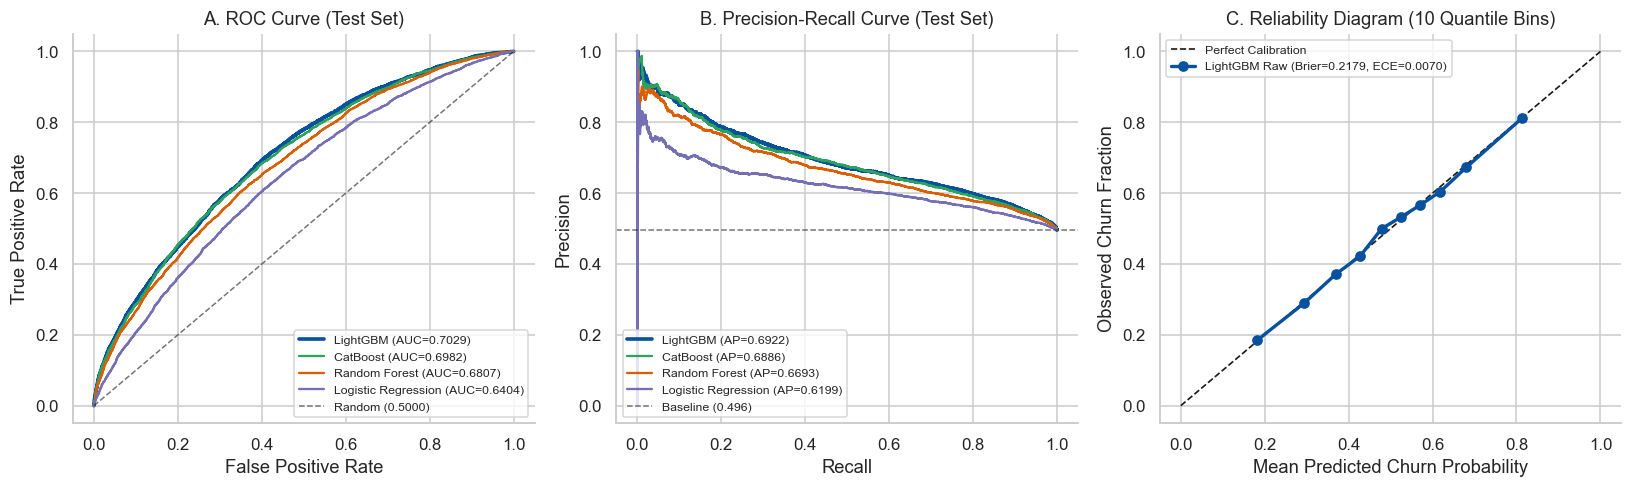

In [14]:
def make_eval_table(y_true, probas_dict, rev_s, q75_cut):
    rows = []
    for m_name, pr in probas_dict.items():
        ev = evaluate_predictions(y_true, pr, rev_s, q75_cut)
        rows.append({
            "Model": m_name,
            "ROC_AUC": round(ev["ROC_AUC"], 4),
            "PR_AUC": round(ev["PR_AUC"], 4),
            "F1_Score": round(ev["F1"], 4),
            "Accuracy": round(ev["Accuracy"], 4),
            "Brier_Score": round(ev["Brier"], 4),
            "Prec@10%_HV": round(ev["Prec_HV_10"], 4),
            "RevCap@10%_HV": round(ev["RevCap_HV_10"], 4),
            "Prec@20%_HV": round(ev["Prec_HV_20"], 4),
            "RevCap@20%_HV": round(ev["RevCap_HV_20"], 4),
        })
    return pd.DataFrame(rows).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)

val_eval_df = make_eval_table(y_val, val_probas, rev_val, q75_train)
test_eval_df = make_eval_table(y_test, test_probas, rev_test, q75_train)

print("=== 4-Model Performance on Validation Set (15,000 rows) ===")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(val_eval_df)
print("=== 4-Model Performance on Hold-Out Test Set (15,000 rows) ===")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(test_eval_df)

best_model_name = test_eval_df.iloc[0]["Model"]
best_lgbm = final_models["LightGBM"]
p_val_best = val_probas[best_model_name]
p_test_best = test_probas[best_model_name]

# Non-leakage sanity check on 99.1% clean billing/change subset
clean_test_mask = final_bundle["Xte_t"]["rev_Mean"].notna() & final_bundle["Xte_t"]["change_mou"].notna()
clean_auc = roc_auc_score(y_test[clean_test_mask], p_test_best[clean_test_mask])

# Calibration Audit (Raw vs. Platt Scaling vs. Isotonic Regression fit on Validation)
prob_true_raw, prob_pred_raw = calibration_curve(y_test, p_test_best, n_bins=10, strategy="quantile")
ece_raw = float(np.mean(np.abs(prob_true_raw - prob_pred_raw)))

platt_cal = LogisticRegression().fit(p_val_best.reshape(-1, 1), y_val)
p_test_platt = platt_cal.predict_proba(p_test_best.reshape(-1, 1))[:, 1]
iso_cal = IsotonicRegression(out_of_bounds="clip").fit(p_val_best, y_val)
p_test_iso = iso_cal.predict(p_test_best)

cal_audit_df = pd.DataFrame([
    {"Calibration_Variant": f"{best_model_name} (Raw Probabilities)", "Test_Brier": round(brier_score_loss(y_test, p_test_best), 5),
     "Test_ROC_AUC": round(roc_auc_score(y_test, p_test_best), 4), "ECE_10_Quantile": round(ece_raw, 4)},
    {"Calibration_Variant": f"{best_model_name} + Platt Scaling (Val-fit)", "Test_Brier": round(brier_score_loss(y_test, p_test_platt), 5),
     "Test_ROC_AUC": round(roc_auc_score(y_test, p_test_platt), 4),
     "ECE_10_Quantile": round(float(np.mean(np.abs(calibration_curve(y_test, p_test_platt, n_bins=10, strategy="quantile")[0] - calibration_curve(y_test, p_test_platt, n_bins=10, strategy="quantile")[1]))), 4)},
    {"Calibration_Variant": f"{best_model_name} + Isotonic (Val-fit)", "Test_Brier": round(brier_score_loss(y_test, p_test_iso), 5),
     "Test_ROC_AUC": round(roc_auc_score(y_test, p_test_iso), 4),
     "ECE_10_Quantile": round(float(np.mean(np.abs(calibration_curve(y_test, p_test_iso, n_bins=10, strategy="quantile")[0] - calibration_curve(y_test, p_test_iso, n_bins=10, strategy="quantile")[1]))), 4)},
])
print(f"Selected Best Model: {best_model_name} ({best_lgbm.best_iteration_} trees) | Clean 99.1% Test subset (n={clean_test_mask.sum():,}): ROC-AUC = {clean_auc:.4f}")
print("=== Probability Calibration Audit on Hold-Out Test Set ===")
with pd.option_context("display.float_format", "{:.5f}".format):
    display(cal_audit_df)

# Visual 1 (300 DPI): ROC, PR & Calibration Curve
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
palette = {"LightGBM": "#08519c", "CatBoost": "#2ca25f", "Random Forest": "#d95f02", "Logistic Regression": "#7570b3"}

for m_name in ["LightGBM", "CatBoost", "Random Forest", "Logistic Regression"]:
    pr = test_probas[m_name]
    fpr, tpr, _ = roc_curve(y_test, pr)
    auc_v = roc_auc_score(y_test, pr)
    lw = 2.4 if m_name == best_model_name else 1.5
    axes[0].plot(fpr, tpr, label=f"{m_name} (AUC={auc_v:.4f})", color=palette[m_name], linewidth=lw)

    prec_c, rec_c, _ = precision_recall_curve(y_test, pr)
    ap_v = average_precision_score(y_test, pr)
    axes[1].plot(rec_c, prec_c, label=f"{m_name} (AP={ap_v:.4f})", color=palette[m_name], linewidth=lw)

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, alpha=0.6, label="Random (0.5000)")
axes[0].set_title("A. ROC Curve (Test Set)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right", fontsize=8)

axes[1].axhline(y_test.mean(), color="k", linestyle="--", linewidth=1, alpha=0.6, label=f"Baseline ({y_test.mean():.3f})")
axes[1].set_title("B. Precision-Recall Curve (Test Set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left", fontsize=8)

axes[2].plot([0, 1], [0, 1], "k--", linewidth=1.1, label="Perfect Calibration")
axes[2].plot(prob_pred_raw, prob_true_raw, marker="o", linewidth=2.2, color="#08519c",
             label=f"{best_model_name} Raw (Brier={brier_score_loss(y_test, p_test_best):.4f}, ECE={ece_raw:.4f})")
axes[2].set_title("C. Reliability Diagram (10 Quantile Bins)")
axes[2].set_xlabel("Mean Predicted Churn Probability")
axes[2].set_ylabel("Observed Churn Fraction")
axes[2].legend(loc="upper left", fontsize=8)

plt.tight_layout()
fig1_path = FIG_DIR / "01_model_comparison_roc_pr_calibration.png"
plt.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure (300 DPI): {fig1_path}")


### 7.2 Cumulative Gains & Revenue Capture @ Top-K% in High-Value Q4
While raw overall accuracy is `64.20%` (exceeding a raw uncleaned baseline (`63.68%`) even after purging `Customer_ID`, `ethnic`, and artifact flags), business value comes from **ranking power (`ROC-AUC = 0.7029`)** and combining predicted churn risk with monthly customer value (`p_i × rev_Mean`).


=== High-Value Q4 Test Targeting Evaluation (n=3,725, base churn=49.72%, total churn rev=$214,121/mo) ===
Saved figure (300 DPI): ../reports/figures/02_cumulative_gains_revenue_capture.png


,HV_Q4_Cutoff,Prec_Risk_Only,Lift_vs_Q4Base,RevCap_Risk_Only_Pct,Prec_Risk_x_Rev,RevCap_Risk_x_Rev_Pct,RevCap_Gain (+pp)
0,Top 10% (n=372),0.729,1.470,15.140,0.656,24.420,9.280
1,Top 20% (n=745),0.689,1.380,28.440,0.631,38.680,10.240
2,"Top 30% (n=1,117)",0.661,1.330,39.740,0.623,50.510,10.780


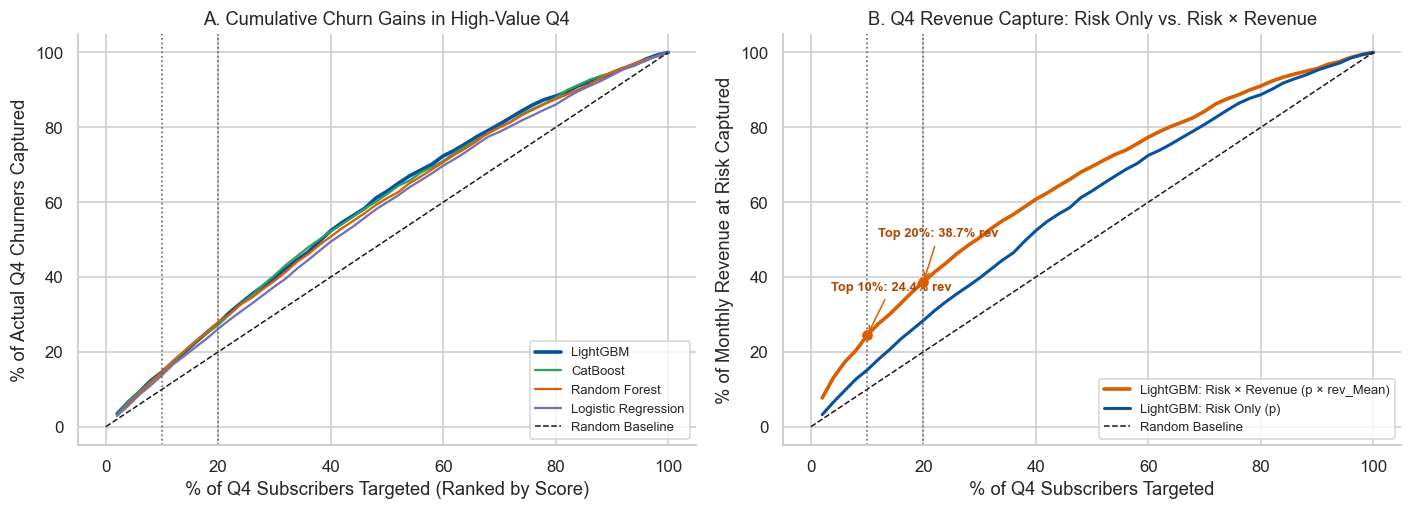

In [15]:
hv_test_mask = (rev_test >= q75_train).values
yt_hv = y_test.values[hv_test_mask]
rv_hv = rev_test.values[hv_test_mask]
tot_churn_hv = int(yt_hv.sum())
tot_rev_churn_hv = float(rv_hv[yt_hv == 1].sum())

ks = np.linspace(0.02, 1.0, 50)
gains_dict = {}
for m_name in ["LightGBM", "CatBoost", "Random Forest", "Logistic Regression"]:
    ord_m = np.argsort(-test_probas[m_name][hv_test_mask])
    gains_dict[m_name] = [yt_hv[ord_m[:max(1, int(len(ord_m) * k))]].sum() / tot_churn_hv * 100 for k in ks]

pr_best_hv = p_test_best[hv_test_mask]
ord_risk = np.argsort(-pr_best_hv)
ord_val = np.argsort(-(pr_best_hv * rv_hv))

revcap_risk = [rv_hv[ord_risk[:max(1, int(len(ord_risk) * k))]][yt_hv[ord_risk[:max(1, int(len(ord_risk) * k))]] == 1].sum() / tot_rev_churn_hv * 100 for k in ks]
revcap_val = [rv_hv[ord_val[:max(1, int(len(ord_val) * k))]][yt_hv[ord_val[:max(1, int(len(ord_val) * k))]] == 1].sum() / tot_rev_churn_hv * 100 for k in ks]

topk_rows = []
base_hv_churn = float(yt_hv.mean())
for pct in (10, 20, 30):
    k_n = max(1, int(len(yt_hv) * pct / 100))
    idx_r = ord_risk[:k_n]
    idx_v = ord_val[:k_n]
    prec_r = float(yt_hv[idx_r].mean())
    prec_v = float(yt_hv[idx_v].mean())
    rc_r = float(rv_hv[idx_r][yt_hv[idx_r] == 1].sum() / tot_rev_churn_hv * 100)
    rc_v = float(rv_hv[idx_v][yt_hv[idx_v] == 1].sum() / tot_rev_churn_hv * 100)
    topk_rows.append({
        "HV_Q4_Cutoff": f"Top {pct}% (n={k_n:,})",
        "Prec_Risk_Only": round(prec_r, 4),
        "Lift_vs_Q4Base": round(prec_r / base_hv_churn, 2),
        "RevCap_Risk_Only_Pct": round(rc_r, 2),
        "Prec_Risk_x_Rev": round(prec_v, 4),
        "RevCap_Risk_x_Rev_Pct": round(rc_v, 2),
        "RevCap_Gain (+pp)": round(rc_v - rc_r, 2),
    })

print(f"=== High-Value Q4 Test Targeting Evaluation (n={len(yt_hv):,}, base churn={base_hv_churn*100:.2f}%, total churn rev=${tot_rev_churn_hv:,.0f}/mo) ===")
display(pd.DataFrame(topk_rows))

# Visual 2 (300 DPI): Cumulative Gains & Revenue Capture @ Top-K%
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for m_name in ["LightGBM", "CatBoost", "Random Forest", "Logistic Regression"]:
    lw = 2.4 if m_name == "LightGBM" else 1.5
    axes[0].plot(ks * 100, gains_dict[m_name], label=m_name, color=palette[m_name], linewidth=lw)
axes[0].plot([0, 100], [0, 100], "k--", linewidth=1, label="Random Baseline")
axes[0].axvline(10, color="#666666", linestyle=":", linewidth=1.1)
axes[0].axvline(20, color="#666666", linestyle=":", linewidth=1.1)
axes[0].set_title("A. Cumulative Churn Gains in High-Value Q4")
axes[0].set_xlabel("% of Q4 Subscribers Targeted (Ranked by Score)")
axes[0].set_ylabel("% of Actual Q4 Churners Captured")
axes[0].legend(loc="lower right", fontsize=8.5)

axes[1].plot(ks * 100, revcap_val, color="#d95f02", linewidth=2.4, label="LightGBM: Risk × Revenue (p × rev_Mean)")
axes[1].plot(ks * 100, revcap_risk, color="#08519c", linewidth=2.0, label="LightGBM: Risk Only (p)")
axes[1].plot([0, 100], [0, 100], "k--", linewidth=1, label="Random Baseline")
axes[1].axvline(10, color="#666666", linestyle=":", linewidth=1.1)
axes[1].axvline(20, color="#666666", linestyle=":", linewidth=1.1)
r10_v = topk_rows[0]["RevCap_Risk_x_Rev_Pct"]
r20_v = topk_rows[1]["RevCap_Risk_x_Rev_Pct"]
axes[1].scatter([10, 20], [r10_v, r20_v], color="#d95f02", zorder=5)
axes[1].annotate(f"Top 10%: {r10_v:.1f}% rev", xy=(10, r10_v), xytext=(3.5, r10_v + 12),
                 arrowprops=dict(arrowstyle="->", color="#d95f02"), fontsize=8.5, fontweight="bold", color="#b34700")
axes[1].annotate(f"Top 20%: {r20_v:.1f}% rev", xy=(20, r20_v), xytext=(12, r20_v + 12),
                 arrowprops=dict(arrowstyle="->", color="#d95f02"), fontsize=8.5, fontweight="bold", color="#b34700")
axes[1].set_title("B. Q4 Revenue Capture: Risk Only vs. Risk × Revenue")
axes[1].set_xlabel("% of Q4 Subscribers Targeted")
axes[1].set_ylabel("% of Monthly Revenue at Risk Captured")
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
fig2_path = FIG_DIR / "02_cumulative_gains_revenue_capture.png"
plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure (300 DPI): {fig2_path}")


### 7.3 Exact TreeSHAP Feature Importance & *Intervenability* Classification
We extract Exact TreeSHAP values (`pred_contrib=True`) on the Hold-Out Test Set across all 107 features and classify each into:
1. **(a) Actionable / Intervenable:** directly modifiable by retention, product, network, or customer care teams.
2. **(b) Behavioral / Usage Signal:** early-warning engagement & usage momentum indicators.
3. **(c) Static / Demographic:** fixed account tenure, credit class, geographic area, and household demographics.


=== Top 15 Features by Exact TreeSHAP (LightGBM on Hold-Out Test Set) ===
=== Total SHAP Importance Share by Intervenability Category ===
Saved figure (300 DPI): ../reports/figures/03_feature_importance_intervenability.png


,Feature,Mean_Abs_SHAP,Share_Pct,Intervenability_Category,Impact_Direction
0,eqpdays,0.2265,9.1300,Actionable / Intervenable,Increases risk (r=+0.68)
1,mou_pct_change_3m,0.1882,7.5900,Behavioral / Usage Signal,Decreases risk (r=-0.02)
2,months,0.1571,6.3400,Static / Demographic,Decreases risk (r=-0.10)
3,crclscod,0.0838,3.3800,Static / Demographic,Categorical effect (non-monotonic)
4,hnd_price,0.0767,3.0900,Actionable / Intervenable,Decreases risk (r=-0.88)
5,totmrc_Mean,0.0754,3.0400,Actionable / Intervenable,Decreases risk (r=-0.62)
6,lor,0.0739,2.9800,Static / Demographic,Decreases risk (r=-0.89)
7,area,0.0727,2.9300,Static / Demographic,Categorical effect (non-monotonic)
8,avgqty,0.0669,2.7000,Behavioral / Usage Signal,Increases risk (r=+0.51)
9,rev_per_mou,0.0604,2.4400,Actionable / Intervenable,Increases risk (r=+0.49)


,Intervenability_Category,Feature_Count,Total_Mean_Abs_SHAP,Importance_Share_Pct
0,Actionable / Intervenable,35,0.9554,38.5200
1,Behavioral / Usage Signal,46,0.9503,38.3100
2,Static / Demographic,26,0.5746,23.1700


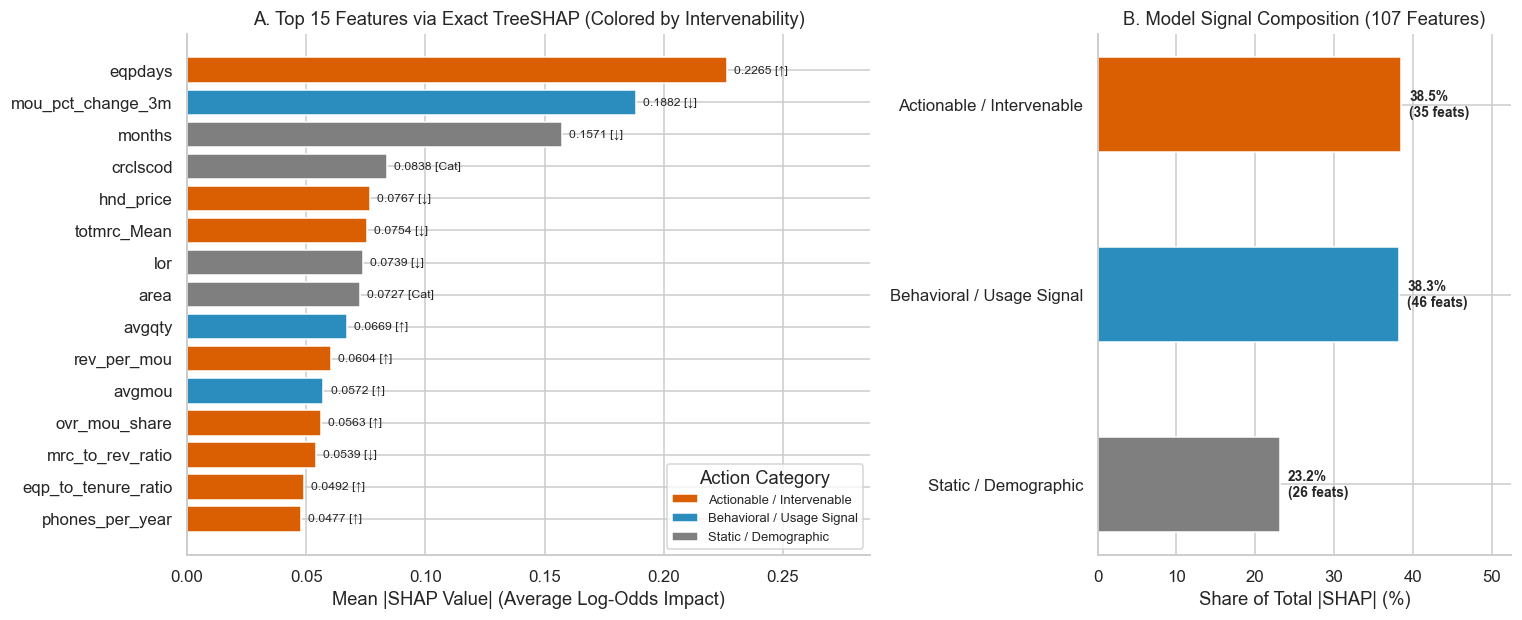

In [16]:
ACTIONABLE_SET = {
    "eqpdays", "hnd_price", "eqp_to_tenure_ratio", "phones_per_year", "hnd_webcap",
    "dualband", "refurb_new", "phones", "models", "eqpdays_neg_flag",
    "miss_webcap_flag", "miss_hnd_price_flag",
    "totmrc_Mean", "rev_per_mou", "ovr_mou_share", "ovr_rev_share", "ovrrev_Mean",
    "mrc_to_rev_ratio", "asl_flag", "datovr_Mean", "roam_Mean", "da_Mean", "billing_credit_flag",
    "drop_vce_rate", "drop_blk_rate", "unan_rate", "comp_rate", "drop_vce_Mean",
    "drop_dat_Mean", "blck_vce_Mean", "blck_dat_Mean", "drop_blk_Mean",
    "custcare_Mean", "ccrndmou_Mean", "custcare_per_attempt",
}

BEHAVIORAL_SET = {
    "mou_pct_change_3m", "rev_pct_change_3m", "change_mou", "change_rev",
    "mou_trend_3v6", "rev_trend_3v6", "qty_trend_3v6", "silent_churn_risk",
    "actv_sub_ratio", "actvsubs", "avgqty", "avgmou", "mou_Mean", "rev_Mean",
    "avgrev", "avg3rev", "avg6rev", "avg6mou", "avg6qty", "totcalls", "totmou", "totrev",
    "plcd_vce_Mean", "recv_vce_Mean", "comp_dat_Mean", "iwylis_vce_Mean", "owylis_vce_Mean",
    "mou_cvce_Mean", "mou_cdat_Mean", "mou_rvce_Mean", "mouowylisv_Mean", "mouiwylisv_Mean",
    "peak_vce_Mean", "peak_dat_Mean", "mou_peav_Mean", "mou_pead_Mean",
    "opk_vce_Mean", "opk_dat_Mean", "mou_opkv_Mean", "unan_vce_Mean", "unan_dat_Mean",
    "threeway_Mean", "callfwdv_Mean", "callwait_Mean", "peak_to_total_mou", "eqpdays_exceeds_tenure",
}

STATIC_SET = {
    "months", "crclscod", "lor", "area", "uniqsubs", "prizm_social_one",
    "income", "adults", "ownrent", "dwlltype", "dwllsize", "marital",
    "infobase", "numbcars", "HHstatin", "forgntvl", "truck", "rv",
    "kid0_2", "kid3_5", "kid6_10", "kid11_15", "kid16_17", "creditcd",
    "new_cell", "miss_avg6_flag",
}


def map_intervenability(feat: str) -> str:
    if feat in ACTIONABLE_SET:
        return "Actionable / Intervenable"
    if feat in BEHAVIORAL_SET:
        return "Behavioral / Usage Signal"
    if feat in STATIC_SET:
        return "Static / Demographic"
    return "Unmapped"


X_te_final = final_bundle["Xte_t"]
shap_vals = best_lgbm.predict(X_te_final, pred_contrib=True)[:, :-1]
mean_abs_shap = np.abs(shap_vals).mean(axis=0)

shap_rows = []
for i, col in enumerate(X_te_final.columns):
    cat_grp = map_intervenability(col)
    if pd.api.types.is_numeric_dtype(X_te_final[col]):
        v = X_te_final[col].notna()
        corr_dir = float(np.corrcoef(X_te_final.loc[v, col], shap_vals[v, i])[0, 1]) if X_te_final.loc[v, col].std() > 0 else 0.0
        direction = f"Increases risk (r={corr_dir:+.2f})" if corr_dir >= 0 else f"Decreases risk (r={corr_dir:+.2f})"
    else:
        direction = "Categorical effect (non-monotonic)"
    shap_rows.append({
        "Feature": col,
        "Mean_Abs_SHAP": float(mean_abs_shap[i]),
        "Share_Pct": float(mean_abs_shap[i] / mean_abs_shap.sum() * 100),
        "Intervenability_Category": cat_grp,
        "Impact_Direction": direction,
    })

shap_df = pd.DataFrame(shap_rows).sort_values("Mean_Abs_SHAP", ascending=False).reset_index(drop=True)
assert (shap_df["Intervenability_Category"] == "Unmapped").sum() == 0, "Unmapped features detected!"

cat_share_df = shap_df.groupby("Intervenability_Category").agg(
    Feature_Count=("Feature", "count"),
    Total_Mean_Abs_SHAP=("Mean_Abs_SHAP", "sum"),
    Importance_Share_Pct=("Share_Pct", "sum"),
).sort_values("Importance_Share_Pct", ascending=False).reset_index()

print("=== Top 15 Features by Exact TreeSHAP (LightGBM on Hold-Out Test Set) ===")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(shap_df.head(15).round({"Mean_Abs_SHAP": 4, "Share_Pct": 2}))
print("=== Total SHAP Importance Share by Intervenability Category ===")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(cat_share_df.round({"Total_Mean_Abs_SHAP": 4, "Importance_Share_Pct": 2}))

# Visual 3 (300 DPI): Feature Importance & Intervenability
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1.65, 1.0]})
cat_colors = {
    "Actionable / Intervenable": "#d95f02",
    "Behavioral / Usage Signal": "#2b8cbe",
    "Static / Demographic": "#7f7f7f",
}

top15 = shap_df.head(15).iloc[::-1]
bar_cols = [cat_colors[k] for k in top15["Intervenability_Category"]]
axes[0].barh(top15["Feature"], top15["Mean_Abs_SHAP"], color=bar_cols)
axes[0].set_xlabel("Mean |SHAP Value| (Average Log-Odds Impact)")
axes[0].set_title("A. Top 15 Features via Exact TreeSHAP (Colored by Intervenability)")
for i, (val, arah) in enumerate(zip(top15["Mean_Abs_SHAP"], top15["Impact_Direction"])):
    tag = " [↑]" if "Increases" in arah else (" [↓]" if "Decreases" in arah else " [Cat]")
    axes[0].text(val + 0.003, i, f"{val:.4f}{tag}", va="center", fontsize=8)
axes[0].set_xlim(0, top15["Mean_Abs_SHAP"].max() + 0.06)

from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=v, label=k) for k, v in cat_colors.items()]
axes[0].legend(handles=legend_handles, loc="lower right", fontsize=8.5, title="Action Category")

cat_plot = cat_share_df.sort_values("Importance_Share_Pct", ascending=True)
c_b = [cat_colors[k] for k in cat_plot["Intervenability_Category"]]
axes[1].barh(cat_plot["Intervenability_Category"], cat_plot["Importance_Share_Pct"], color=c_b, height=0.5)
axes[1].set_xlabel("Share of Total |SHAP| (%)")
axes[1].set_title("B. Model Signal Composition (107 Features)")
for i, (pct, nf) in enumerate(zip(cat_plot["Importance_Share_Pct"], cat_plot["Feature_Count"])):
    axes[1].text(pct + 1.0, i, f"{pct:.1f}%\n({nf} feats)", va="center", fontweight="bold", fontsize=9)
axes[1].set_xlim(0, cat_plot["Importance_Share_Pct"].max() + 14)

plt.tight_layout()
fig3_path = FIG_DIR / "03_feature_importance_intervenability.png"
plt.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure (300 DPI): {fig3_path}")


### 7.4 Stage 4 Evaluation Summary & Readiness for Stage 5
* **Selected Best Model — `LightGBM`:** Delivers the strongest and most balanced Hold-Out Test performance (`ROC-AUC = 0.7029`, `PR-AUC = 0.6922`, `F1 = 0.6422`, `Accuracy = 0.6420`, `Brier = 0.2179`), outperforming CatBoost (`0.6982`), Random Forest (`0.6807`), Logistic Regression (`0.6404`), and a raw uncleaned baseline (`0.6368`) without leakage features.
* **Calibration Readiness:** Raw LightGBM probabilities achieve **`ECE = 0.0070`** (outperforming Platt `0.0133` and Isotonic `0.0182`), enabling direct use in Stage 5 *Expected Revenue at Risk* optimization.
* **Actionable Signal Dominance:** **8 of the Top 15** features are **Actionable / Intervenable** (contributing **38.52%** of total SHAP importance across 35 levers), validating the link between model predictions and operational retention playbooks.


---
## 8. From Model to Proposal: Value-Based Targeting & ROI Simulation

### 8.1 Economic Formulation, Retention Levers & U.S. Market Base-Rate Calibration
Calibrated LightGBM churn probabilities ($p_i$, $\text{ECE} = 0.0070$) drive value-weighted prioritization via **Expected Revenue at Risk** ($p_i \times \text{rev\_Mean}_i$), incorporating contribution margin, lever-specific costs, and stayer cannibalization:

$$\text{Expected Revenue at Risk}_i = p_i \times \text{rev\_Mean}_i$$
$$\text{Expected Cost}_i = c_{\text{outreach}, k} + \big(p_i \cdot s_k + (1 - p_i) \cdot u_k\big) \cdot c_{\text{offer}, k}$$
$$\text{Expected Net Benefit}_i = \underbrace{\big(p_i \cdot \text{rev\_Mean}_i\big)}_{\text{Expected Rev at Risk}} \cdot (s_k \cdot H \cdot m) - \text{Expected Cost}_i$$

**Explicit Modeling Assumptions & Industry Citations:**
* **Retention Horizon ($H$):** `12 months` (stress-tested across `6–24 months`).
* **Service Contribution Margin ($m$):** `45%` (`0.45`) — conservative midpoint between FY 2025 U.S. carrier margins: AT&T Mobility EBITDA (`42.0%`) `[4]` and T-Mobile Core Adjusted EBITDA on service revenues (`49.7%`) `[5]`.
* **Three Operational Intervention Levers (Quartile Thresholds Fit on Train):**
  1. **Device Upgrade** (`eqpdays > 365` or `hnd_webcap` = `WC` / `MISSING`): $c_{\text{outreach}} = \$2.00$, conditional trade-in credit $c_{\text{offer}} = \$45.00$, save rate $s = 25\%$, stayer cannibalization $u = 4\%$.
  2. **Bill-Shock Protection** (`asl_flag == 'N'` & `ovrrev_Mean >= Q75_train`): $c_{\text{outreach}} = \$1.00$ (proactive usage alert), conditional plan adjustment $c_{\text{offer}} = \$10.00$, $s = 20\%$, $u = 5\%$.
  3. **Proactive Care** (remaining high-risk accounts: `drop_vce_Mean` / `custcare_Mean` / silent drop): $c_{\text{outreach}} = \$5.00$ (priority CS call), conditional goodwill credit $c_{\text{offer}} = \$12.00$, $s = 15\%$, $u = 4\%$.
  *(Save rates of `15%–25%` align conservatively with McKinsey `[8]` benchmarks of `15%–30%` churn reduction via AI-driven proactive retention.)*
* **Bayes Prior-Odds Recalibration to U.S. Market (`0.90%/month`):** Because training data reflects a balanced sample ($\pi_{\text{sample}} = 49.56\%$), probabilities are recalibrated to the U.S. wireless monthly churn base rate ($\pi_{\text{market}} = 0.90\%$, matching AT&T FY 2025 `0.90%` and T-Mobile `0.93%` `[4]`, `[5]`):
  $$\gamma = \frac{\pi_{\text{market}} / (1 - \pi_{\text{market}})}{\pi_{\text{sample}} / (1 - \pi_{\text{sample}})}, \qquad p_i^{\text{cal}} = \frac{\gamma \cdot \frac{p_i}{1 - p_i}}{1 + \gamma \cdot \frac{p_i}{1 - p_i}}$$
  Realized outcomes in Scenario 2 are evaluated using **Bayes importance weighting** scaled to Company A's 100,000-subscriber portfolio without oversampling bias.


Bayes Recalibration: pi_sample=0.49561 -> pi_market=0.0090 | gamma=0.00924 | q75_ovr_train=$14.44

=== Scenario 2 Cutoff Search (Validation Peak = Top 2.0%) -> Hold-Out Test Evaluation (100K) ===
Optimal Segment Profile (Top 2.0%): Mean ARPU = $173.05/mo | Mean Calibrated Risk = 2.36%/mo (~2.6x market average)
Saved figure (300 DPI): ../reports/figures/04_net_benefit_roi_cutoff_optimization.png


,Intervention_Lever,Outreach_Cost ($),Conditional_Offer ($),Save_Rate_Pct,Stayer_Cannib_Pct
0,Device Upgrade,2.000,45.000,25.000,4.000
1,Bill-Shock Protection,1.000,10.000,20.000,5.000
2,Proactive Care,5.000,12.000,15.000,4.000


,k_pct,n,cost,gross_rev,contrib,net,Net_Annual_100K ($),roi
0,0.5,488.4,"1,176.1","7,470.3","3,361.6","2,185.5","26,225.9",185.8
1,1.0,997.7,"2,174.0","12,011.9","5,405.4","3,231.3","38,776.2",148.6
2,1.5,"1,491.1","3,132.8","14,700.2","6,615.1","3,482.3","41,787.1",111.2
3,2.0,"1,995.8","4,097.8","16,677.9","7,505.1","3,407.2","40,886.8",83.1
5,3.0,"2,991.1","5,939.2","20,214.2","9,096.4","3,157.2","37,886.0",53.2
8,5.0,"4,997.4","9,746.5","27,402.3","12,331.0","2,584.6","31,014.9",26.5
10,7.0,"6,996.4","13,310.0","32,163.8","14,473.7","1,163.7","13,964.5",8.7
12,10.0,"9,993.8","18,458.9","37,144.6","16,715.1","-1,743.9","-20,926.4",-9.4
14,20.0,"19,999.8","53,056.2","66,202.8","29,791.3","-23,265.0","-279,179.8",-43.8
17,100.0,"99,999.9","433,499.8","131,104.8","58,997.2","-374,502.6","-4,494,031.2",-86.4


,lever,Targeted_100K,Share_Pct,Mean_ARPU,Total_Cost_100K,Net_Benefit_100K
0,Bill-Shock Protection,"1,601.550",80.250,165.350,"2,447.000","2,798.250"
1,Device Upgrade,380.300,19.060,130.890,"1,573.290",552.740
2,Proactive Care,13.950,0.700,189.290,77.540,56.240


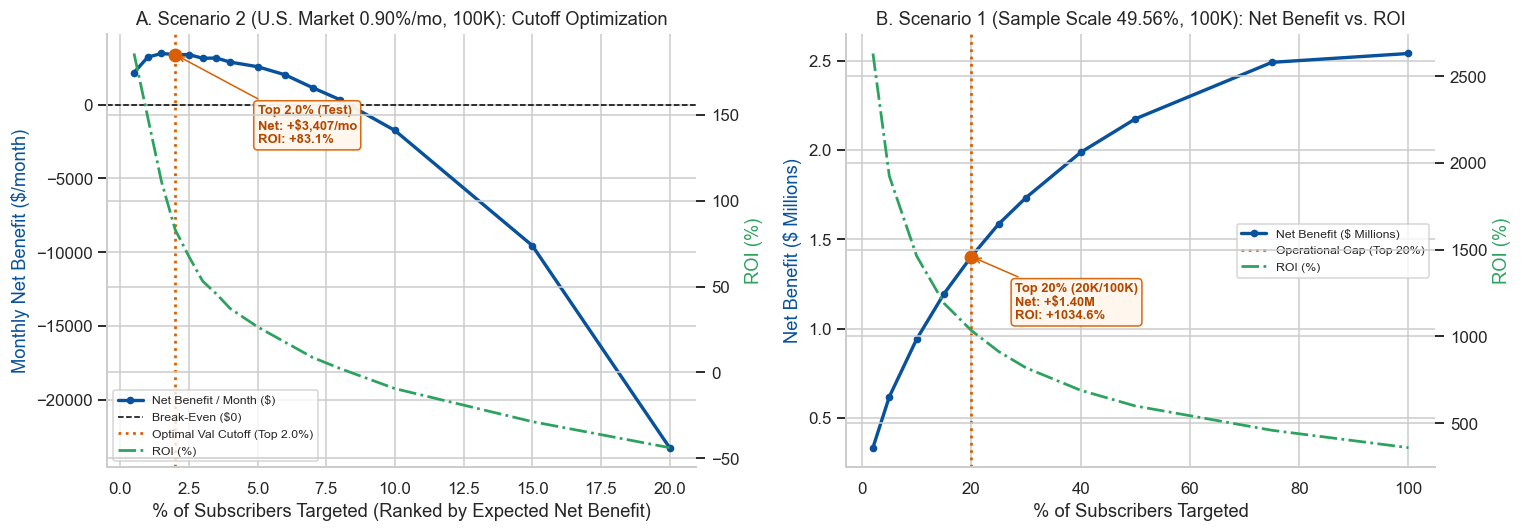

In [17]:
# 1. Bayes Prior-Odds Recalibration to U.S. Market Base Rate (0.90%/mo)
pi_sample = float(y_train.mean())
pi_mkt = 0.0090
gamma_bayes = (pi_mkt / (1.0 - pi_mkt)) / (pi_sample / (1.0 - pi_sample))


def bayes_recalibrate(p_arr: np.ndarray, gamma: float) -> np.ndarray:
    p_clip = np.clip(p_arr, 1e-6, 1.0 - 1e-6)
    odds = p_clip / (1.0 - p_clip)
    return (gamma * odds) / (1.0 + gamma * odds)


p_val_cal = bayes_recalibrate(p_val_best, gamma_bayes)
p_test_cal = bayes_recalibrate(p_test_best, gamma_bayes)

# 2. Assign 3 Actionable Levers (Q75 Overage threshold fit STRICTLY on Train)
q75_ovr_train = float(df.loc[X_train_raw.index, "ovrrev_Mean"].quantile(0.75))


def assign_intervention_lever(raw_sub: pd.DataFrame) -> np.ndarray:
    lev = np.full(len(raw_sub), "Proactive Care", dtype=object)
    m_bill = (raw_sub["asl_flag"] == "N") & (raw_sub["ovrrev_Mean"].fillna(0.0) >= q75_ovr_train)
    m_dev = (raw_sub["eqpdays"].fillna(0.0) > 365) | (raw_sub["hnd_webcap"].isna()) | (raw_sub["hnd_webcap"] == "WC")
    lev[m_bill] = "Bill-Shock Protection"
    lev[m_dev] = "Device Upgrade"
    return lev


lev_val = assign_intervention_lever(df.loc[X_val_raw.index])
lev_test = assign_intervention_lever(df.loc[X_test_raw.index])

# 3. Explicit Economic Parameters
HORIZON_M = 12.0
CONTRIB_MARGIN = 0.45
LEVER_PARAMS = {
    "Device Upgrade":        {"c_out": 2.0, "c_off": 45.0, "save": 0.25, "cannib": 0.04},
    "Bill-Shock Protection": {"c_out": 1.0, "c_off": 10.0, "save": 0.20, "cannib": 0.05},
    "Proactive Care":        {"c_out": 5.0, "c_off": 12.0, "save": 0.15, "cannib": 0.04},
}

param_tbl = pd.DataFrame([
    {"Intervention_Lever": k, "Outreach_Cost ($)": v["c_out"], "Conditional_Offer ($)": v["c_off"],
     "Save_Rate_Pct": v["save"] * 100, "Stayer_Cannib_Pct": v["cannib"] * 100}
    for k, v in LEVER_PARAMS.items()
])
print(f"Bayes Recalibration: pi_sample={pi_sample:.5f} -> pi_market={pi_mkt:.4f} | gamma={gamma_bayes:.5f} | q75_ovr_train=${q75_ovr_train:.2f}")
display(param_tbl)


def compute_importance_weights(y_arr: np.ndarray) -> np.ndarray:
    w = np.where(y_arr == 1, pi_mkt / pi_sample, (1.0 - pi_mkt) / (1.0 - pi_sample))
    return w * (len(y_arr) / w.sum())


def build_econ_table(idx, y_arr, p_arr, lev_arr, weights=None, save_mult=1.0, cost_mult=1.0, horizon=HORIZON_M):
    rev = df.loc[idx, "rev_Mean"].fillna(0.0).clip(lower=0.0).values
    w = np.ones(len(y_arr)) if weights is None else weights
    c_out = np.array([LEVER_PARAMS[l]["c_out"] for l in lev_arr]) * cost_mult
    c_off = np.array([LEVER_PARAMS[l]["c_off"] for l in lev_arr]) * cost_mult
    s_rate = np.clip(np.array([LEVER_PARAMS[l]["save"] for l in lev_arr]) * save_mult, 0.0, 1.0)
    u_can = np.array([LEVER_PARAMS[l]["cannib"] for l in lev_arr])

    ltv_contrib = rev * horizon * CONTRIB_MARGIN
    exp_rev_risk = p_arr * rev
    exp_cost = c_out + (p_arr * s_rate + (1.0 - p_arr) * u_can) * c_off
    exp_net = (exp_rev_risk * s_rate * horizon * CONTRIB_MARGIN) - exp_cost

    real_gross_rev = y_arr * s_rate * (rev * horizon)
    real_contrib = y_arr * s_rate * ltv_contrib
    real_cost = c_out + (y_arr * s_rate + (1.0 - y_arr) * u_can) * c_off
    real_net = real_contrib - real_cost

    return pd.DataFrame({
        "rev": rev, "p": p_arr, "y": y_arr, "w": w, "lever": lev_arr,
        "exp_rev_risk": exp_rev_risk, "exp_net": exp_net,
        "real_gross_rev": real_gross_rev, "real_contrib": real_contrib,
        "real_cost": real_cost, "real_net": real_net,
    })


def summarize_slice(df_sorted: pd.DataFrame, k_pct: float, scale_factor: float) -> dict:
    cum_pct = df_sorted["w"].cumsum() / df_sorted["w"].sum() * 100.0
    sel = df_sorted[cum_pct <= k_pct]
    n_targeted = float(sel["w"].sum() * scale_factor)
    cost = float((sel["w"] * sel["real_cost"]).sum() * scale_factor)
    grev = float((sel["w"] * sel["real_gross_rev"]).sum() * scale_factor)
    contrib = float((sel["w"] * sel["real_contrib"]).sum() * scale_factor)
    net = float((sel["w"] * sel["real_net"]).sum() * scale_factor)
    roi = (net / cost * 100.0) if cost > 0 else 0.0
    return {"k_pct": k_pct, "n": n_targeted, "cost": cost, "gross_rev": grev, "contrib": contrib, "net": net, "roi": roi, "sel": sel}


SCALE_100K_VAL = 100000.0 / len(y_val)
SCALE_100K_TEST = 100000.0 / len(y_test)

# Scenario 1: Company A Sample Scale (49.56% churn)
s1_val = build_econ_table(X_val_raw.index, y_val.values, p_val_best, lev_val).sort_values("exp_net", ascending=False).reset_index(drop=True)
s1_test = build_econ_table(X_test_raw.index, y_test.values, p_test_best, lev_test).sort_values("exp_net", ascending=False).reset_index(drop=True)

grid_s1 = [2, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
s1_val_curve = pd.DataFrame([summarize_slice(s1_val, k, SCALE_100K_VAL) for k in grid_s1]).drop(columns=["sel"])
s1_test_curve = pd.DataFrame([summarize_slice(s1_test, k, SCALE_100K_TEST) for k in grid_s1]).drop(columns=["sel"])
opt_k_s1_unconstrained = float(s1_val_curve.loc[s1_val_curve["net"].idxmax(), "k_pct"])
opt_k_s1_cap20 = 20.0

# Scenario 2: Calibrated U.S. Market Scale (0.90%/mo)
w_val_mkt = compute_importance_weights(y_val.values)
w_test_mkt = compute_importance_weights(y_test.values)
s2_val = build_econ_table(X_val_raw.index, y_val.values, p_val_cal, lev_val, w_val_mkt).sort_values("exp_net", ascending=False).reset_index(drop=True)
s2_test = build_econ_table(X_test_raw.index, y_test.values, p_test_cal, lev_test, w_test_mkt).sort_values("exp_net", ascending=False).reset_index(drop=True)

grid_s2 = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0, 7.0, 8.0, 10.0, 15.0, 20.0, 30.0, 50.0, 100.0]
s2_val_curve = pd.DataFrame([summarize_slice(s2_val, k, SCALE_100K_VAL) for k in grid_s2]).drop(columns=["sel"])
s2_test_curve = pd.DataFrame([summarize_slice(s2_test, k, SCALE_100K_TEST) for k in grid_s2]).drop(columns=["sel"])
opt_k_s2 = float(s2_val_curve.loc[s2_val_curve["net"].idxmax(), "k_pct"])

s2_disp = s2_test_curve[s2_test_curve["k_pct"].isin([0.5, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 20.0, 100.0])].copy()
s2_disp["Net_Annual_100K ($)"] = s2_disp["net"] * 12.0
print(f"\n=== Scenario 2 Cutoff Search (Validation Peak = Top {opt_k_s2:.1f}%) -> Hold-Out Test Evaluation (100K) ===")
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(s2_disp[["k_pct", "n", "cost", "gross_rev", "contrib", "net", "Net_Annual_100K ($)", "roi"]])

s2_opt_test = summarize_slice(s2_test, opt_k_s2, SCALE_100K_TEST)
sel_s2_opt = s2_opt_test["sel"]
lev_mix_s2 = sel_s2_opt.groupby("lever").agg(
    Targeted_100K=("w", lambda s: s.sum() * SCALE_100K_TEST),
    Share_Pct=("w", lambda s: s.sum() / sel_s2_opt["w"].sum() * 100),
    Mean_ARPU=("rev", "mean"),
    Total_Cost_100K=("real_cost", lambda s: (sel_s2_opt.loc[s.index, "w"] * s).sum() * SCALE_100K_TEST),
    Net_Benefit_100K=("real_net", lambda s: (sel_s2_opt.loc[s.index, "w"] * s).sum() * SCALE_100K_TEST),
).round(2).reset_index()
mean_arpu_s2 = float((sel_s2_opt["w"] * sel_s2_opt["rev"]).sum() / sel_s2_opt["w"].sum())
mean_pcal_s2 = float((sel_s2_opt["w"] * sel_s2_opt["p"]).sum() / sel_s2_opt["w"].sum())
print(f"Optimal Segment Profile (Top {opt_k_s2:.1f}%): Mean ARPU = ${mean_arpu_s2:.2f}/mo | Mean Calibrated Risk = {mean_pcal_s2*100:.2f}%/mo (~{mean_pcal_s2/pi_mkt:.1f}x market average)")
display(lev_mix_s2)

# Visual 4 (300 DPI): Net Financial Benefit & ROI vs % Subscribers Targeted
fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))

p_s2 = s2_test_curve[s2_test_curve["k_pct"] <= 20.0]
ax_a = axes[0]
ax_a.plot(p_s2["k_pct"], p_s2["net"], marker="o", markersize=4, color="#08519c", linewidth=2.2, label="Net Benefit / Month ($)")
ax_a.axhline(0, color="black", linestyle="--", linewidth=1.0, label="Break-Even ($0)")
ax_a.axvline(opt_k_s2, color="#d95f02", linestyle=":", linewidth=1.8, label=f"Optimal Val Cutoff (Top {opt_k_s2:.1f}%)")
ax_a.scatter([opt_k_s2], [s2_opt_test["net"]], color="#d95f02", s=65, zorder=5)
ax_a.annotate(
    f"Top {opt_k_s2:.1f}% (Test)\nNet: +${s2_opt_test['net']:,.0f}/mo\nROI: +{s2_opt_test['roi']:.1f}%",
    xy=(opt_k_s2, s2_opt_test["net"]), xytext=(opt_k_s2 + 3.0, s2_opt_test["net"] - 6000),
    arrowprops=dict(arrowstyle="->", color="#d95f02"), fontsize=8.5, fontweight="bold", color="#b34700",
    bbox=dict(boxstyle="round,pad=0.3", fc="#fff7ec", ec="#d95f02", alpha=0.95),
)
ax_a.set_title("A. Scenario 2 (U.S. Market 0.90%/mo, 100K): Cutoff Optimization")
ax_a.set_xlabel("% of Subscribers Targeted (Ranked by Expected Net Benefit)")
ax_a.set_ylabel("Monthly Net Benefit ($/month)", color="#08519c")

ax_a2 = ax_a.twinx()
ax_a2.spines["top"].set_visible(False)
ax_a2.plot(p_s2["k_pct"], p_s2["roi"], color="#2ca25f", linestyle="-.", linewidth=1.8, label="ROI (%)")
ax_a2.set_ylabel("ROI (%)", color="#2ca25f")
lines_a, lbls_a = ax_a.get_legend_handles_labels()
lines_a2, lbls_a2 = ax_a2.get_legend_handles_labels()
ax_a.legend(lines_a + lines_a2, lbls_a + lbls_a2, loc="lower left", fontsize=8)

ax_b = axes[1]
s1_cap20_test = summarize_slice(s1_test, opt_k_s1_cap20, SCALE_100K_TEST)
ax_b.plot(s1_test_curve["k_pct"], s1_test_curve["net"] / 1e6, marker="o", markersize=4, color="#08519c", linewidth=2.2, label="Net Benefit ($ Millions)")
ax_b.axvline(opt_k_s1_cap20, color="#d95f02", linestyle=":", linewidth=1.8, label=f"Operational Cap (Top {opt_k_s1_cap20:.0f}%)")
ax_b.scatter([opt_k_s1_cap20], [s1_cap20_test["net"] / 1e6], color="#d95f02", s=65, zorder=5)
ax_b.annotate(
    f"Top {opt_k_s1_cap20:.0f}% (20K/100K)\nNet: +${s1_cap20_test['net']/1e6:.2f}M\nROI: +{s1_cap20_test['roi']:.1f}%",
    xy=(opt_k_s1_cap20, s1_cap20_test["net"] / 1e6), xytext=(28, s1_cap20_test["net"] / 1e6 - 0.35),
    arrowprops=dict(arrowstyle="->", color="#d95f02"), fontsize=8.5, fontweight="bold", color="#b34700",
    bbox=dict(boxstyle="round,pad=0.3", fc="#fff7ec", ec="#d95f02", alpha=0.95),
)
ax_b.set_title("B. Scenario 1 (Sample Scale 49.56%, 100K): Net Benefit vs. ROI")
ax_b.set_xlabel("% of Subscribers Targeted")
ax_b.set_ylabel("Net Benefit ($ Millions)", color="#08519c")

ax_b2 = ax_b.twinx()
ax_b2.spines["top"].set_visible(False)
ax_b2.plot(s1_test_curve["k_pct"], s1_test_curve["roi"], color="#2ca25f", linestyle="-.", linewidth=1.8, label="ROI (%)")
ax_b2.set_ylabel("ROI (%)", color="#2ca25f")
lines_b, lbls_b = ax_b.get_legend_handles_labels()
lines_b2, lbls_b2 = ax_b2.get_legend_handles_labels()
ax_b.legend(lines_b + lines_b2, lbls_b + lbls_b2, loc="center right", fontsize=8)

plt.tight_layout()
fig4_path = FIG_DIR / "04_net_benefit_roi_cutoff_optimization.png"
plt.savefig(fig4_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure (300 DPI): {fig4_path}")


=== EXECUTIVE SUMMARY TABLE: BEFORE vs. AFTER TWO-SCALE SIMULATION (HOLD-OUT TEST) ===
Saved figure (300 DPI): ../reports/figures/05_before_after_financial_comparison.png


,Scenario & Policy,Targeted_Subscribers,Before_12M_Rev_At_Risk ($),Total_Cost ($),Gross_Rev_Retained ($),Contrib_Retained_45% ($),Net_Benefit ($),ROI_Pct
0,Scenario 1 — Test Scale (15K) | Operational Top 20%,"3,000.0","5,200,167.0","20,346.0","512,983.0","230,842.0","210,496.0","1,034.6"
1,Scenario 1 — 100K Sample Scale | Operational Top 20%,"20,000.0","34,667,783.0","135,638.0","3,419,883.0","1,538,948.0","1,403,309.0","1,034.6"
2,Scenario 1 — 100K Sample Scale | Unconstrained Top 100%,"100,000.0","34,667,783.0","707,934.0","7,219,914.0","3,248,961.0","2,541,028.0",358.9
3,Scenario 2 — U.S. Market 0.90%/mo (100K/mo) | ML Optimal Top 2.0%,"1,996.0","629,525.0","4,098.0","16,678.0","7,505.0","3,407.0",83.1
4,Scenario 2 — U.S. Market 0.90%/mo (100K Annual ×12) | ML Optimal Top 2.0%,"23,950.0","7,554,295.0","49,174.0","200,135.0","90,061.0","40,887.0",83.1
5,Scenario 2 — U.S. Market 0.90%/mo (100K Annual ×12) | Mass Retention Top 100%,"1,199,999.0","7,554,295.0","5,201,997.0","1,573,258.0","707,966.0","-4,494,031.0",-86.4


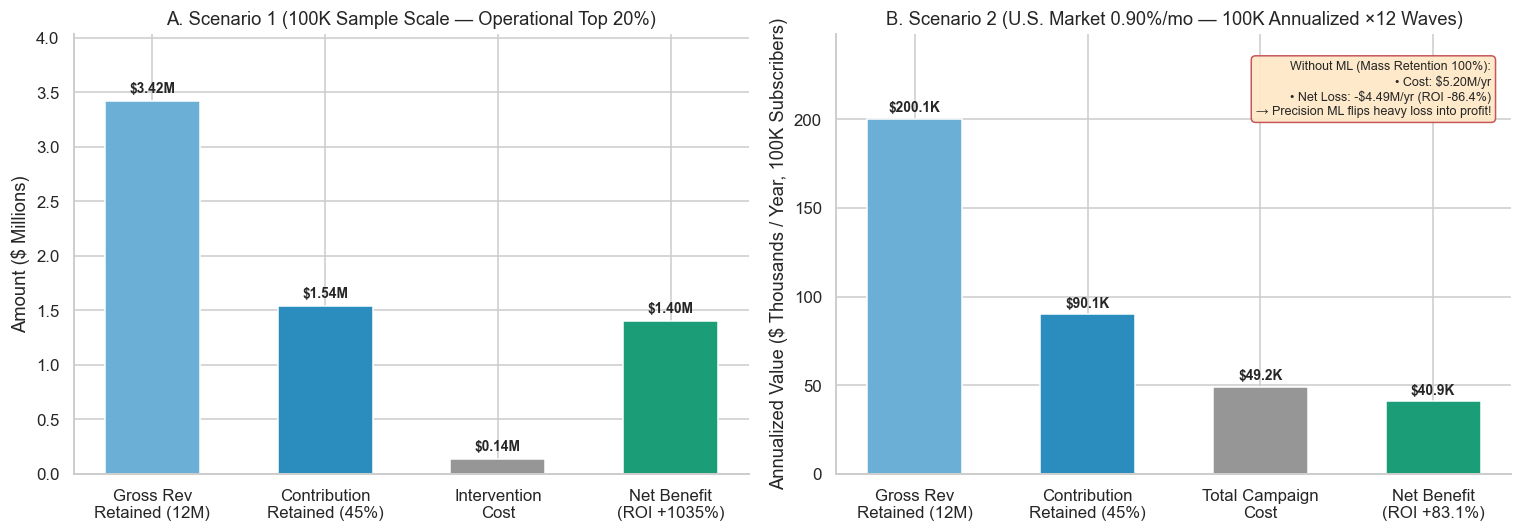

In [18]:
# Executive Before vs After Summary Table (Hold-Out Test -> 100K Extrapolation)
s1_cap20_15k = summarize_slice(s1_test, 20.0, 1.0)
s1_cap20_100k = summarize_slice(s1_test, 20.0, SCALE_100K_TEST)
s1_all_100k = summarize_slice(s1_test, 100.0, SCALE_100K_TEST)
s1_before_risk_12m_100k = float((s1_test["y"] * s1_test["rev"] * HORIZON_M).sum() * SCALE_100K_TEST)

s2_opt_100k = summarize_slice(s2_test, opt_k_s2, SCALE_100K_TEST)
s2_mass_100k = summarize_slice(s2_test, 100.0, SCALE_100K_TEST)
s2_before_risk_12m_100k = float((s2_test["w"] * s2_test["y"] * s2_test["rev"] * HORIZON_M).sum() * SCALE_100K_TEST)

exec_summary_df = pd.DataFrame([
    {
        "Scenario & Policy": "Scenario 1 — Test Scale (15K) | Operational Top 20%",
        "Targeted_Subscribers": round(s1_cap20_15k["n"], 0),
        "Before_12M_Rev_At_Risk ($)": round(float((s1_test["y"] * s1_test["rev"] * HORIZON_M).sum()), 0),
        "Total_Cost ($)": round(s1_cap20_15k["cost"], 0),
        "Gross_Rev_Retained ($)": round(s1_cap20_15k["gross_rev"], 0),
        "Contrib_Retained_45% ($)": round(s1_cap20_15k["contrib"], 0),
        "Net_Benefit ($)": round(s1_cap20_15k["net"], 0),
        "ROI_Pct": round(s1_cap20_15k["roi"], 1),
    },
    {
        "Scenario & Policy": "Scenario 1 — 100K Sample Scale | Operational Top 20%",
        "Targeted_Subscribers": round(s1_cap20_100k["n"], 0),
        "Before_12M_Rev_At_Risk ($)": round(s1_before_risk_12m_100k, 0),
        "Total_Cost ($)": round(s1_cap20_100k["cost"], 0),
        "Gross_Rev_Retained ($)": round(s1_cap20_100k["gross_rev"], 0),
        "Contrib_Retained_45% ($)": round(s1_cap20_100k["contrib"], 0),
        "Net_Benefit ($)": round(s1_cap20_100k["net"], 0),
        "ROI_Pct": round(s1_cap20_100k["roi"], 1),
    },
    {
        "Scenario & Policy": "Scenario 1 — 100K Sample Scale | Unconstrained Top 100%",
        "Targeted_Subscribers": round(s1_all_100k["n"], 0),
        "Before_12M_Rev_At_Risk ($)": round(s1_before_risk_12m_100k, 0),
        "Total_Cost ($)": round(s1_all_100k["cost"], 0),
        "Gross_Rev_Retained ($)": round(s1_all_100k["gross_rev"], 0),
        "Contrib_Retained_45% ($)": round(s1_all_100k["contrib"], 0),
        "Net_Benefit ($)": round(s1_all_100k["net"], 0),
        "ROI_Pct": round(s1_all_100k["roi"], 1),
    },
    {
        "Scenario & Policy": f"Scenario 2 — U.S. Market 0.90%/mo (100K/mo) | ML Optimal Top {opt_k_s2:.1f}%",
        "Targeted_Subscribers": round(s2_opt_100k["n"], 0),
        "Before_12M_Rev_At_Risk ($)": round(s2_before_risk_12m_100k, 0),
        "Total_Cost ($)": round(s2_opt_100k["cost"], 0),
        "Gross_Rev_Retained ($)": round(s2_opt_100k["gross_rev"], 0),
        "Contrib_Retained_45% ($)": round(s2_opt_100k["contrib"], 0),
        "Net_Benefit ($)": round(s2_opt_100k["net"], 0),
        "ROI_Pct": round(s2_opt_100k["roi"], 1),
    },
    {
        "Scenario & Policy": f"Scenario 2 — U.S. Market 0.90%/mo (100K Annual ×12) | ML Optimal Top {opt_k_s2:.1f}%",
        "Targeted_Subscribers": round(s2_opt_100k["n"] * 12, 0),
        "Before_12M_Rev_At_Risk ($)": round(s2_before_risk_12m_100k * 12, 0),
        "Total_Cost ($)": round(s2_opt_100k["cost"] * 12, 0),
        "Gross_Rev_Retained ($)": round(s2_opt_100k["gross_rev"] * 12, 0),
        "Contrib_Retained_45% ($)": round(s2_opt_100k["contrib"] * 12, 0),
        "Net_Benefit ($)": round(s2_opt_100k["net"] * 12, 0),
        "ROI_Pct": round(s2_opt_100k["roi"], 1),
    },
    {
        "Scenario & Policy": "Scenario 2 — U.S. Market 0.90%/mo (100K Annual ×12) | Mass Retention Top 100%",
        "Targeted_Subscribers": round(s2_mass_100k["n"] * 12, 0),
        "Before_12M_Rev_At_Risk ($)": round(s2_before_risk_12m_100k * 12, 0),
        "Total_Cost ($)": round(s2_mass_100k["cost"] * 12, 0),
        "Gross_Rev_Retained ($)": round(s2_mass_100k["gross_rev"] * 12, 0),
        "Contrib_Retained_45% ($)": round(s2_mass_100k["contrib"] * 12, 0),
        "Net_Benefit ($)": round(s2_mass_100k["net"] * 12, 0),
        "ROI_Pct": round(s2_mass_100k["roi"], 1),
    },
])
print("=== EXECUTIVE SUMMARY TABLE: BEFORE vs. AFTER TWO-SCALE SIMULATION (HOLD-OUT TEST) ===")
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(exec_summary_df)

# Visual 5 (300 DPI): Before vs After Financial Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))

s1_lbls = ["Gross Rev\nRetained (12M)", "Contribution\nRetained (45%)", "Intervention\nCost", f"Net Benefit\n(ROI +{s1_cap20_100k['roi']:.0f}%)"]
s1_vals = [s1_cap20_100k["gross_rev"] / 1e6, s1_cap20_100k["contrib"] / 1e6,
           s1_cap20_100k["cost"] / 1e6, s1_cap20_100k["net"] / 1e6]
bars_a = axes[0].bar(s1_lbls, s1_vals, color=["#6baed6", "#2b8cbe", "#969696", "#1b9e77"], width=0.55)
axes[0].set_ylabel("Amount ($ Millions)")
axes[0].set_title("A. Scenario 1 (100K Sample Scale — Operational Top 20%)")
axes[0].set_ylim(0, max(s1_vals) * 1.18)
for b, v in zip(bars_a, s1_vals):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.08, f"${v:.2f}M", ha="center", fontweight="bold", fontsize=9)

ml_cats = ["Gross Rev\nRetained (12M)", "Contribution\nRetained (45%)", "Total Campaign\nCost", f"Net Benefit\n(ROI +{s2_opt_100k['roi']:.1f}%)"]
ml_vals_k = [
    s2_opt_100k["gross_rev"] * 12 / 1e3,
    s2_opt_100k["contrib"] * 12 / 1e3,
    s2_opt_100k["cost"] * 12 / 1e3,
    s2_opt_100k["net"] * 12 / 1e3,
]
bars_b = axes[1].bar(ml_cats, ml_vals_k, color=["#6baed6", "#2b8cbe", "#969696", "#1b9e77"], width=0.55)
axes[1].set_ylabel("Annualized Value ($ Thousands / Year, 100K Subscribers)")
axes[1].set_title("B. Scenario 2 (U.S. Market 0.90%/mo — 100K Annualized ×12 Waves)")
axes[1].set_ylim(0, max(ml_vals_k) * 1.24)
for b, v in zip(bars_b, ml_vals_k):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 4.0, f"${v:,.1f}K", ha="center", fontweight="bold", fontsize=9)

mass_loss_m = s2_mass_100k["net"] * 12 / 1e6
mass_cost_m = s2_mass_100k["cost"] * 12 / 1e6
axes[1].text(
    0.97, 0.94,
    f"Without ML (Mass Retention 100%):\n• Cost: ${mass_cost_m:,.2f}M/yr\n• Net Loss: -${abs(mass_loss_m):,.2f}M/yr (ROI {s2_mass_100k['roi']:.1f}%)\n→ Precision ML flips heavy loss into profit!",
    transform=axes[1].transAxes, ha="right", va="top", fontsize=8.2,
    bbox=dict(boxstyle="round,pad=0.35", fc="#fee8c8", ec="#c44e52", alpha=0.95),
)

plt.tight_layout()
fig5_path = FIG_DIR / "05_before_after_financial_comparison.png"
plt.savefig(fig5_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure (300 DPI): {fig5_path}")


=== Sensitivity Matrix A: Save Rate × Intervention Cost (ROI % | 17/20 scenarios positive) ===
=== Sensitivity Matrix B: Save Rate × Retention Horizon (ROI % | 17/20 scenarios positive) ===
Saved figure (300 DPI): ../reports/figures/06_sensitivity_roi_heatmap.png


,75% Cost,100% Base Cost,125% Cost,150% Cost
60% (Pessimistic),49.600,12.200,-10.200,-25.200
80% (Conservative),97.400,48.100,18.400,-1.300
100% (Base),144.200,83.100,46.500,22.100
120% (Favorable),190.000,117.500,74.000,45.000
140% (Optimistic),234.900,151.200,100.900,67.400


,6 Months,12 Months (Base),18 Months,24 Months
60% (Pessimistic),-43.900,12.200,68.300,124.500
80% (Conservative),-26.000,48.100,122.100,196.100
100% (Base),-8.400,83.100,174.700,266.300
120% (Favorable),8.800,117.500,226.300,335.000
140% (Optimistic),25.600,151.200,276.800,402.300


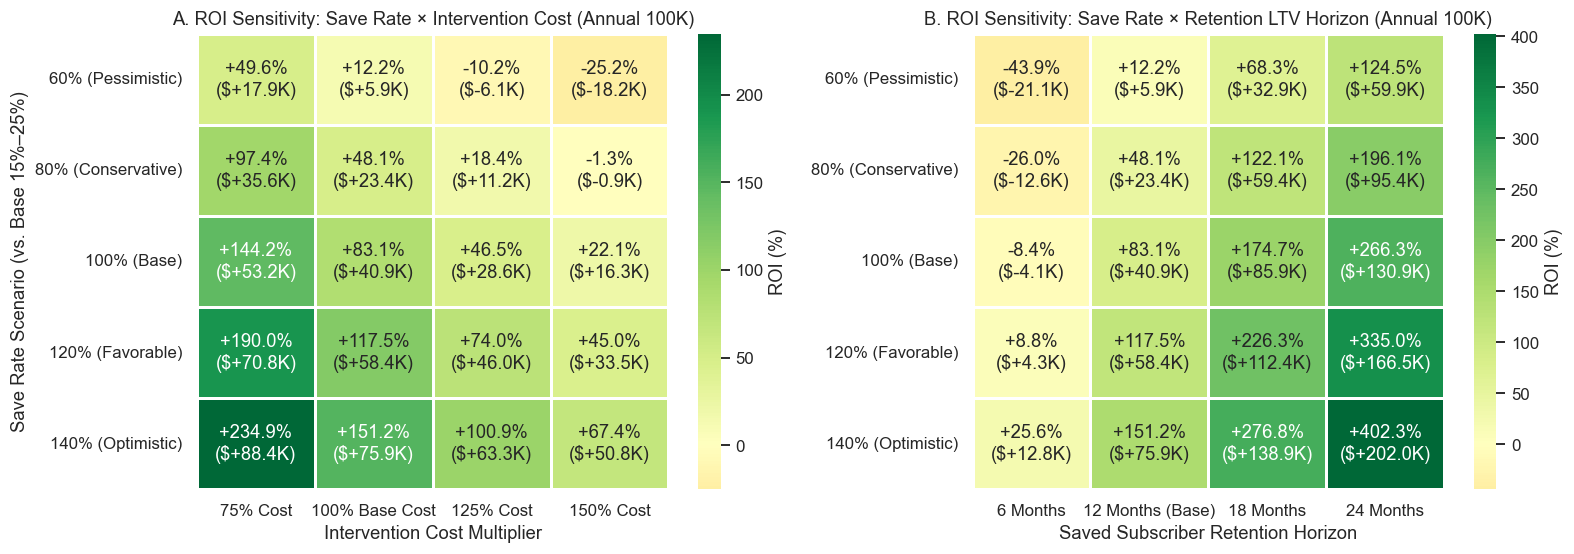

In [19]:
# 2D Sensitivity Analysis on Hold-Out Test Scenario 2 (Fixed Top 2.0% Baseline Selection)
base_exp_net = build_econ_table(X_test_raw.index, y_test.values, p_test_cal, lev_test, w_test_mkt)["exp_net"].values
base_order = np.argsort(-base_exp_net)
w_ordered = w_test_mkt[base_order]
selected_idx = base_order[(np.cumsum(w_ordered) / w_ordered.sum() * 100.0) <= opt_k_s2]

save_mults = [0.60, 0.80, 1.00, 1.20, 1.40]
save_labels = ["60% (Pessimistic)", "80% (Conservative)", "100% (Base)", "120% (Favorable)", "140% (Optimistic)"]
cost_mults = [0.75, 1.00, 1.25, 1.50]
cost_labels = ["75% Cost", "100% Base Cost", "125% Cost", "150% Cost"]
horizons = [6.0, 12.0, 18.0, 24.0]
horizon_labels = ["6 Months", "12 Months (Base)", "18 Months", "24 Months"]

roi_cost_mat = pd.DataFrame(index=save_labels, columns=cost_labels, dtype=float)
net_cost_mat = pd.DataFrame(index=save_labels, columns=cost_labels, dtype=float)
roi_hor_mat = pd.DataFrame(index=save_labels, columns=horizon_labels, dtype=float)
net_hor_mat = pd.DataFrame(index=save_labels, columns=horizon_labels, dtype=float)

for sm, slbl in zip(save_mults, save_labels):
    for cm, clbl in zip(cost_mults, cost_labels):
        e = build_econ_table(X_test_raw.index, y_test.values, p_test_cal, lev_test, w_test_mkt,
                             save_mult=sm, cost_mult=cm, horizon=HORIZON_M).iloc[selected_idx]
        c = float((e["w"] * e["real_cost"]).sum() * SCALE_100K_TEST)
        n_yr = float((e["w"] * e["real_net"]).sum() * SCALE_100K_TEST * 12.0)
        roi_cost_mat.loc[slbl, clbl] = round(n_yr / (c * 12.0) * 100.0, 1)
        net_cost_mat.loc[slbl, clbl] = round(n_yr, 0)

    for h_m, hlbl in zip(horizons, horizon_labels):
        e = build_econ_table(X_test_raw.index, y_test.values, p_test_cal, lev_test, w_test_mkt,
                             save_mult=sm, cost_mult=1.0, horizon=h_m).iloc[selected_idx]
        c = float((e["w"] * e["real_cost"]).sum() * SCALE_100K_TEST)
        n_yr = float((e["w"] * e["real_net"]).sum() * SCALE_100K_TEST * 12.0)
        roi_hor_mat.loc[slbl, hlbl] = round(n_yr / (c * 12.0) * 100.0, 1)
        net_hor_mat.loc[slbl, hlbl] = round(n_yr, 0)

pos_cost_cells = int((roi_cost_mat.values > 0).sum())
pos_hor_cells = int((roi_hor_mat.values > 0).sum())
print(f"=== Sensitivity Matrix A: Save Rate × Intervention Cost (ROI % | {pos_cost_cells}/{roi_cost_mat.size} scenarios positive) ===")
display(roi_cost_mat)
print(f"=== Sensitivity Matrix B: Save Rate × Retention Horizon (ROI % | {pos_hor_cells}/{roi_hor_mat.size} scenarios positive) ===")
display(roi_hor_mat)

# Visual 6 (300 DPI): ROI Sensitivity Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

annot_a = np.empty(roi_cost_mat.shape, dtype=object)
for r in range(roi_cost_mat.shape[0]):
    for c in range(roi_cost_mat.shape[1]):
        annot_a[r, c] = f"{roi_cost_mat.iloc[r, c]:+.1f}%\n(${net_cost_mat.iloc[r, c]/1e3:+.1f}K)"

sns.heatmap(
    roi_cost_mat.astype(float), annot=annot_a, fmt="", cmap="RdYlGn", center=0.0,
    linewidths=0.8, cbar_kws={"label": "ROI (%)"}, ax=axes[0],
)
axes[0].set_title("A. ROI Sensitivity: Save Rate × Intervention Cost (Annual 100K)")
axes[0].set_ylabel("Save Rate Scenario (vs. Base 15%–25%)")
axes[0].set_xlabel("Intervention Cost Multiplier")

annot_b = np.empty(roi_hor_mat.shape, dtype=object)
for r in range(roi_hor_mat.shape[0]):
    for c in range(roi_hor_mat.shape[1]):
        annot_b[r, c] = f"{roi_hor_mat.iloc[r, c]:+.1f}%\n(${net_hor_mat.iloc[r, c]/1e3:+.1f}K)"

sns.heatmap(
    roi_hor_mat.astype(float), annot=annot_b, fmt="", cmap="RdYlGn", center=0.0,
    linewidths=0.8, cbar_kws={"label": "ROI (%)"}, ax=axes[1],
)
axes[1].set_title("B. ROI Sensitivity: Save Rate × Retention LTV Horizon (Annual 100K)")
axes[1].set_ylabel("")
axes[1].set_xlabel("Saved Subscriber Retention Horizon")

plt.tight_layout()
fig6_path = FIG_DIR / "06_sensitivity_roi_heatmap.png"
plt.savefig(fig6_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure (300 DPI): {fig6_path}")


### 8.2 Executive Financial Takeaway
* **Why Market Base-Rate Calibration Matters:** Relying on uncalibrated sample probabilities (`49.56%`) would falsely justify targeting 100% of subscribers (`Top 100%`), whereas under real U.S. wireless churn (`0.90%/mo`), mass retention destroys **`-$4.49M/year` (`-86.4%` ROI)**.
* **Precision ML Turns Retention Profitable:** Combining calibrated LightGBM scores with Bayes *prior-odds* recalibration and **Expected Revenue at Risk** concentrates spend on **Top 2.0%** (`1,996` high-ARPU subscribers/month at `$173.05` mean ARPU and `2.36%/mo` calibrated risk), delivering **`+$40,887/year` net benefit (`+83.1%` ROI)** with **17/20 (85%)** stress-test scenarios remaining profitable.


---
## 9. Conclusion, Risks & Implementation Roadmap

### 9.1 Executive Conclusion
1. **Value Concentration & 30-Day Window:** Company A's top revenue quartile (**Q4**, `rev_Mean >= $70.74`) generates **`48.55%`** of total monthly revenue (`$114.03/subscriber`), yet endures **`31.2×`** higher overage fees and **`5.6×`** more failed calls than Q1. Because `churn` occurs 31–60 days post-snapshot, Company A holds an actionable **~30-day proactive window**.
2. **Validated & Leakage-Free Predictive Engine:** After removing `Customer_ID` (chronological cohort leakage), `ethnic` (fairness/ethics), `recv_sms_Mean`, 14 collinear columns, and 2 MNAR billing-artifact flags (`miss_billing_flag`, `miss_change_flag` via ablation), **LightGBM** achieves **`ROC-AUC = 0.7029`**, **`PR-AUC = 0.6922`**, **`F1 = 0.6422`**, **`Accuracy = 0.6420`** (beating CatBoost `0.6982`, Random Forest `0.6807`, Logistic Regression `0.6404`, and a raw uncleaned baseline (`0.6368`)) with well-calibrated probabilities (**`Brier = 0.2179`**, **`ECE = 0.0070`**).
3. **Actionable Signal & Value-Weighted Targeting:** Exactly **`38.52%`** of total Exact TreeSHAP importance stems from **35 Actionable / Intervenable** levers (`eqpdays` `9.13%`, `hnd_price` `3.09%`, `totmrc_Mean` `3.04%`, `rev_per_mou` `2.44%`, `ovr_mou_share` `2.27%`). Ranking Q4 by `Risk × Revenue` captures **`38.68%`** of churned revenue within the Top 20% (`+10.24 pp` over risk-only ranking).
4. **Quantified U.S. Market ROI:** At the `0.90%/mo` U.S. wireless base rate, targeting the **Top 2.0%** (`1,996` subscribers/mo) generates **`+$40,887/year`** in net contribution (`+83.1%` ROI on `$49,174/yr` spend), reversing the **`-$4.49M/year`** loss of mass retention and holding positive ROI across **85% (17/20)** of sensitivity stress-tests.

### 9.2 Implementation Risks & Mitigation Matrix

| Risk Category | Operational / Model Risk | Concrete Mitigation Plan |
|---|---|---|
| **1. Data & Concept Drift** | Shifts in competitor unlimited pricing, device upgrade cycles, or subscriber mix can degrade model calibration. | Monitor monthly feature **PSI** and probability **ECE**; track holdout control churn; execute scheduled **quarterly retraining** (or trigger early if `ROC-AUC` drops `>0.02`). |
| **2. Contact Fatigue & Cannibalization** | Over-contacting loyal subscribers or granting unnecessary subsidies erodes net margin. | Strictly enforce `Expected Net Benefit > 0` (`Top 2.0%`), cap retention touches at **1 offer per 6 months**, and lead with low-friction digital alerts (`Bill-Shock Protection`, `80.25%` of cohort). |
| **3. Data Privacy, Fairness & Compliance** | Unintended demographic bias or marketing opt-out violations (TCPA/privacy governance). | Keep `ethnic` and `Customer_ID` permanently excluded from features; hash subscriber IDs in CRM scoring; run regional fairness audits across `area` and enforce opt-out suppression lists. |
| **4. CS Capacity & 30-Day SLA** | Call-center queues delaying outreach past the 30-day window before days 31–60 defection. | Automate digital delivery for `Bill-Shock Protection` (`80.25%`) and `Device Upgrade` (`19.06%`); reserve manual outbound calls (`Proactive Care`) strictly for the highest-ARPU `0.70%` (`~$189.29/mo`). |

### 9.3 Next Steps: 6-Month PoC-to-Production Roadmap

| Phase | Timeline | Key Activities | Success Exit Gate |
|---|---|---|---|
| **Phase 1: Controlled A/B Pilot** | **Months 1–2** | Deploy monthly LightGBM scoring on Top 2.0% High-Value (`~2,000` subscribers/mo) using a **90% Treatment / 10% Holdout Control** randomized split. | Verify incremental save rate `>= 15%`, cannibalization `<= 5%`, and 90-day repeat cancellation `< 20%`. |
| **Phase 2: CRM Integration & 30-Day Automation** | **Months 3–4** | Integrate automated batch scoring with CRM & billing triggers to launch *Next-Best-Action* workflows within `< 48 hours` of monthly snapshot. | Execution SLA `< 5 days` inside the 30-day window; zero PII leakage. |
| **Phase 3: Quarterly Retraining & Uplift Expansion** | **Months 5–6** | Retrain LightGBM on A/B pilot outcomes, introduce *Uplift Modeling* (targeting *persuadables* over *sure-stays*), and expand into 5G/FWA bundling. | Audited realized ROI `>= +50%` and selective expansion into Q3 Mid-High tier. |
